<a href="https://colab.research.google.com/github/victorcetre/Redes-Neuronales-y-Deep-Learning/blob/main/07MIAR_Proyecto_Graphs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"

## Clasificación de tipos de gráficos con redes convolucionales

Autor: Victor Cetre

## Planteamiento del problema

En análisis de datos mucha información útil está dentro de informes, presentaciones y artículos en forma de gráficos, no en tablas. Para extraer automáticamente los valores de un gráfico primero hay que saber de qué tipo es, porque una tarta, unas barras o una tabla se leen de forma distinta. Este trabajo resuelve ese primer paso: dada una imagen, decidir a cuál de ocho categorías pertenece.

Se comparan dos estrategias con el mismo conjunto de datos y la misma partición:

- una CNN diseñada y entrenada desde cero, que se va ajustando experimento a experimento;
- dos redes preentrenadas en ImageNet (MobileNetV2 y ResNet50V2), primero como extractor de características (*transfer learning*) y después con *fine-tuning* progresivo.

Todas las cifras y figuras de este documento se generan al ejecutar el notebook.

## Selección del conjunto de datos

Se usa el [Graphs Dataset](https://www.kaggle.com/datasets/sunedition/graphs-dataset) de Kaggle (autor SunEdition, licencia CC0). Contiene unas 15.900 imágenes de gráficos recogidas de la web y repartidas en ocho clases: `bar_chart`, `diagram`, `flow_chart`, `graph`, `growth_chart`, `just_image`, `pie_chart` y `table`. La clase `just_image` agrupa imágenes que no son gráficos.

Motivos de la elección:

- el tema conecta con el análisis de datos, que es el área de trabajo del autor;
- el tamaño permite entrenar una CNN desde cero sin que el sobreajuste sea inmediato y, a la vez, cabe en una GPU de Colab;
- son imágenes reales, con tamaños, formatos y estilos muy variados (capturas, clipart, figuras de artículos). Eso obliga a un preprocesamiento cuidadoso y hace que la comparación entre estrategias sea informativa, porque el problema no se resuelve trivialmente.

La etiqueta de cada imagen está en el prefijo del nombre de archivo (`bar_chart_...`, `pie_chart_...`). El número de imágenes por clase, su distribución y sus dimensiones se analizan más abajo, en la inspección de los datos.

## Configuración del entorno

El notebook funciona igual en Google Colab y en un equipo local (Linux o WSL). Detecta dónde se ejecuta y ajusta las rutas y las credenciales de Kaggle. En Colab los datos se copian al disco de la máquina virtual, que es mucho más rápido que Drive, y los resultados (modelos, historiales y el PDF) se guardan en Drive.

Si hay GPU se activa la precisión mixta (`mixed_float16`): los cálculos se hacen en 16 bits y los pesos se guardan en 32, lo que acelera el entrenamiento en las GPU T4 de Colab casi al doble sin pérdida apreciable de precisión.

In [ ]:
import os, io, sys, gc, json, time, hashlib, shutil, subprocess, warnings, contextlib
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')   # oculta los mensajes internos de TensorFlow/CUDA
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.dummy import DummyClassifier
from IPython.display import display

import tensorflow as tf
import keras
from keras import layers, regularizers

SEED = 42
keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel('ERROR')    # oculta avisos internos de TensorFlow que no afectan al resultado

Image.MAX_IMAGE_PIXELS = None        # hay imágenes de la web muy grandes
warnings.filterwarnings('ignore', module='PIL')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 3)

# Paleta fija para todas las figuras (cada clase o serie conserva siempre su color)
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 10, 'lines.linewidth': 2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

In [ ]:
try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# Con PRUEBA_RAPIDA = True el notebook se recorre entero con pocas imágenes y 2 épocas por
# experimento. Sirve para comprobar que todo funciona antes de lanzar la ejecución completa.
PRUEBA_RAPIDA = False

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_FOLDER = Path('/content/drive/MyDrive/Colab Notebooks/07MIAR_Proyecto_Programacion')
    DATOS = Path('/content/datos')
else:
    BASE_FOLDER = Path.home() / '07MIAR_Proyecto_Programacion'
    DATOS = BASE_FOLDER / 'datos'

RESULTADOS = BASE_FOLDER / 'resultados'
for carpeta in (BASE_FOLDER, DATOS, RESULTADOS):
    carpeta.mkdir(parents=True, exist_ok=True)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
if gpus:
    keras.mixed_precision.set_global_policy('mixed_float16')

print('Entorno:', 'Google Colab' if EN_COLAB else 'local')
print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
print('GPU:', [tf.config.experimental.get_device_details(g).get('device_name', g.name) for g in gpus] or 'ninguna')
print('Política de precisión:', keras.mixed_precision.global_policy().name)
print('Carpeta de resultados:', RESULTADOS)
if PRUEBA_RAPIDA:
    print('\nATENCIÓN: PRUEBA_RAPIDA está activada. Estos resultados no sirven para la entrega.')

Mounted at /content/drive
Entorno: Google Colab
TensorFlow 2.21.0 | Keras 3.13.2
GPU: ['Tesla T4']
Política de precisión: mixed_float16
Carpeta de resultados: /content/drive/MyDrive/Colab Notebooks/07MIAR_Proyecto_Programacion/resultados


Parámetros generales. La CNN desde cero trabaja con imágenes de 128×128 para que cada experimento tarde pocos minutos; las redes preentrenadas usan 224×224, la resolución con la que se entrenaron en ImageNet. Todos los entrenamientos usan *early stopping* sobre la pérdida de validación y recuperan los pesos de la mejor época.

In [ ]:
TAM_GUARDADO = 224      # tamaño al que se guardan las imágenes ya limpias
TAM_SCRATCH = 128       # entrada de la CNN desde cero
TAM_PRE = 224           # entrada de las redes preentrenadas
BATCH_SCRATCH = 64
BATCH_PRE = 32

EPOCAS_SCRATCH = 30
EPOCAS_SCRATCH_LARGO = 50   # experimentos con aumento de datos, que convergen más despacio
PACIENCIA_SCRATCH = 6
EPOCAS_TL = 15
EPOCAS_FT = 15
PACIENCIA_PRE = 4
MAX_POR_CLASE = None

if PRUEBA_RAPIDA:
    EPOCAS_SCRATCH = EPOCAS_SCRATCH_LARGO = EPOCAS_TL = EPOCAS_FT = 2
    MAX_POR_CLASE = 40

## Carga del conjunto de datos

La descarga se hace con la API de Kaggle mediante una función reutilizable. Si el dataset ya está en disco, no se vuelve a descargar.

Las credenciales en Colab se leen de los secretos del notebook (icono de la llave de la barra lateral): `KAGGLE_USERNAME` y `KAGGLE_KEY`, o bien `KAGGLE_API_TOKEN` con el formato nuevo de token de Kaggle. Así la clave no aparece en ninguna salida. En local se usa el fichero de credenciales de `~/.kaggle`.

In [ ]:
SLUG = 'sunedition/graphs-dataset'
DESCARGA = DATOS / 'original'


def configurar_kaggle():
    # En local la CLI de Kaggle lee sola ~/.kaggle/kaggle.json (o ~/.kaggle/access_token).
    if EN_COLAB:
        from google.colab import userdata
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--upgrade', 'kaggle'], check=True)
        for clave in ('KAGGLE_USERNAME', 'KAGGLE_KEY', 'KAGGLE_API_TOKEN'):
            try:
                os.environ[clave] = userdata.get(clave)
            except Exception:
                pass    # se usa el par usuario/clave o el token nuevo, según cuál esté definido


def descargar_dataset(slug, destino):
    # Descarga y descomprime un dataset de Kaggle en `destino` y devuelve la lista de ficheros.
    destino.mkdir(parents=True, exist_ok=True)
    if any(p.is_file() for p in destino.rglob('*')):
        print('Dataset ya descargado en', destino)
    else:
        configurar_kaggle()
        kaggle_cli = shutil.which('kaggle') or str(Path(sys.executable).parent / 'kaggle')
        t0 = time.time()
        subprocess.run([kaggle_cli, 'datasets', 'download', '-d', slug, '-p', str(destino), '--unzip', '-q'],
                       check=True)
        print(f'Descargado en {time.time() - t0:.0f} s')
    archivos = sorted(p for p in destino.rglob('*') if p.is_file())
    print(f'{len(archivos)} ficheros')
    return archivos


archivos = descargar_dataset(SLUG, DESCARGA)

Descargado en 72 s
15875 ficheros


## Inspección y análisis del conjunto de datos

Se abre cada fichero con Pillow para obtener su clase, formato real, modo de color, dimensiones y una huella MD5 del contenido. La huella permite encontrar imágenes repetidas, que podrían acabar a la vez en entrenamiento y en test e inflar las métricas.

La clase se obtiene del prefijo del nombre. Se comparan primero los prefijos más largos para que ninguno se confunda con otro parecido.

In [ ]:
CLASES = ['bar_chart', 'diagram', 'flow_chart', 'graph', 'growth_chart', 'just_image', 'pie_chart', 'table']
N_CLASES = len(CLASES)
COLOR_CLASE = dict(zip(CLASES, COLORES))


def clase_desde_nombre(nombre):
    for c in sorted(CLASES, key=len, reverse=True):
        if nombre.startswith(c + '_'):
            return c
    return None


def inspeccionar(ruta):
    info = dict(ruta=str(ruta), clase=clase_desde_nombre(ruta.name), extension=ruta.suffix.lower(),
                kb=ruta.stat().st_size / 1024, formato=None, modo=None, ancho=np.nan, alto=np.nan,
                frames=1, legible=False, error=None)
    try:
        with Image.open(ruta) as im:
            info.update(formato=im.format, modo=im.mode, ancho=im.width, alto=im.height,
                        frames=getattr(im, 'n_frames', 1))
            im.load()   # decodifica la imagen completa para detectar ficheros dañados
        info['legible'] = True
    except Exception as e:
        info['error'] = type(e).__name__
    info['md5'] = hashlib.md5(ruta.read_bytes()).hexdigest()
    return info


if MAX_POR_CLASE:
    rng = np.random.default_rng(SEED)
    por_clase = {}
    for p in archivos:
        por_clase.setdefault(clase_desde_nombre(p.name), []).append(p)
    archivos = [p for lista in por_clase.values()
                for p in rng.permutation(lista)[:MAX_POR_CLASE]]

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    df = pd.DataFrame(list(ex.map(inspeccionar, archivos)))
print(f'{len(df)} ficheros inspeccionados en {time.time() - t0:.0f} s')
print('Ficheros sin clase reconocible:', df.clase.isna().sum())
display(df.head())

15875 ficheros inspeccionados en 48 s
Ficheros sin clase reconocible: 0


,ruta,clase,extension,kb,formato,modo,ancho,alto,frames,legible,error,md5
0,/content/datos/original/graphs/bar_chart_0006-...,bar_chart,.jpg,115.174,JPEG,RGB,960,720,1,True,None,9ea57197664f40069e597efa418a87cd
1,/content/datos/original/graphs/bar_chart_008.j...,bar_chart,.jpg,119.309,JPEG,RGB,960,720,1,True,None,7ccb3115dad37cdd72db0287daf061d1
2,/content/datos/original/graphs/bar_chart_013d0...,bar_chart,.jpg,74.793,JPEG,RGB,960,720,1,True,None,2e75f683891ce557b5b7d5d5d90b12e7
3,/content/datos/original/graphs/bar_chart_016f9...,bar_chart,.jpg,114.863,JPEG,RGB,1024,767,1,True,None,6d5510fd9a63ae7781f1483ca237c948
4,/content/datos/original/graphs/bar_chart_0183d...,bar_chart,.jpg,26.776,JPEG,RGB,350,271,1,True,None,e3f96dc17c8cbbfe271144b8936ae5be


### Distribución de las clases

,imágenes,%
clase,,
bar_chart,1981,12.5
diagram,2005,12.6
flow_chart,1708,10.8
graph,1910,12.0
growth_chart,1175,7.4
just_image,3174,20.0
pie_chart,1857,11.7
table,2065,13.0


Total: 15875 imágenes | clase mayor / clase menor = 2.70


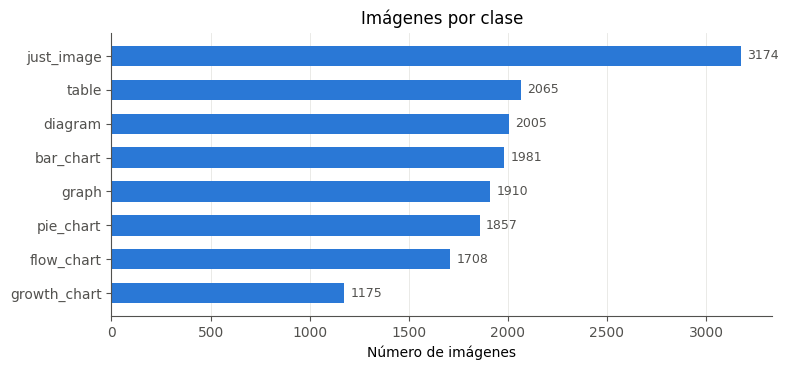

In [ ]:
conteo = df.clase.value_counts().reindex(CLASES).fillna(0).astype(int)
display(pd.DataFrame({'imágenes': conteo, '%': (100 * conteo / conteo.sum()).round(1)}))
DESBALANCE = conteo.max() / conteo.min()
print(f'Total: {conteo.sum()} imágenes | clase mayor / clase menor = {DESBALANCE:.2f}')

orden = conteo.sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(orden.index, orden.values, color=COLORES[0], height=0.6)
for i, v in enumerate(orden.values):
    ax.text(v + conteo.max() * 0.01, i, str(v), va='center', fontsize=9, color='#52514e')
ax.set_xlabel('Número de imágenes')
ax.set_title('Imágenes por clase')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

### Formatos y modos de color

La extensión del fichero no siempre coincide con su formato real, y hay imágenes en paleta, en escala de grises o con transparencia. Esto condiciona cómo hay que leerlas.

In [ ]:
print('Ficheros que no se pueden abrir:', (~df.legible).sum())
if (~df.legible).any():
    display(df[~df.legible].error.value_counts())
display(pd.crosstab(df.extension, df.formato.fillna('ilegible')))
display(df.modo.value_counts(dropna=False).rename('imágenes'))
print('Imágenes animadas (más de un fotograma):', (df.frames > 1).sum())

Ficheros que no se pueden abrir: 0


formato,GIF,JPEG,PNG,WEBP
extension,,,,
.gif,3,0,0,0
.jpeg,0,2,0,0
.jpg,0,15773,0,0
.png,0,0,96,0
.webp,0,0,0,1


,imágenes
modo,
RGB,15872
P,3


Imágenes animadas (más de un fotograma): 0


### Dimensiones de las imágenes

,ancho,alto,kb
count,15875.0,15875.0,15875.0
mean,449.0,345.0,67.0
std,478.0,379.0,267.0
min,29.0,48.0,1.0
5%,168.0,133.0,7.0
50%,275.0,205.0,18.0
95%,1240.0,934.0,232.0
max,7682.0,5775.0,15807.0


Imágenes con el lado menor por debajo de 64 px: 3
Imágenes con el lado menor por debajo de 32 px: 1


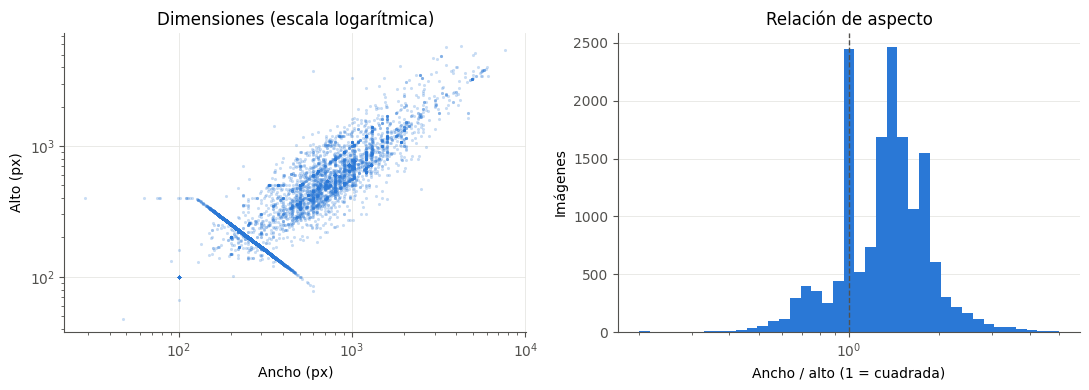

In [ ]:
ok = df[df.legible].copy()
ok['lado_menor'] = ok[['ancho', 'alto']].min(axis=1)
ok['aspecto'] = ok.ancho / ok.alto
display(ok[['ancho', 'alto', 'kb']].describe(percentiles=[.05, .5, .95]).round(0))
print('Imágenes con el lado menor por debajo de 64 px:', (ok.lado_menor < 64).sum())
print('Imágenes con el lado menor por debajo de 32 px:', (ok.lado_menor < 32).sum())

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].scatter(ok.ancho, ok.alto, s=5, alpha=0.25, color=COLORES[0], linewidths=0)
axs[0].set_xscale('log'); axs[0].set_yscale('log')
axs[0].set_xlabel('Ancho (px)'); axs[0].set_ylabel('Alto (px)')
axs[0].set_title('Dimensiones (escala logarítmica)')
bins = np.logspace(np.log10(0.2), np.log10(5), 40)
axs[1].hist(ok.aspecto.clip(0.2, 5), bins=bins, color=COLORES[0])
axs[1].axvline(1, color='#52514e', linestyle='--', linewidth=1)
axs[1].set_xscale('log')
axs[1].set_xlabel('Ancho / alto (1 = cuadrada)'); axs[1].set_ylabel('Imágenes')
axs[1].set_title('Relación de aspecto')
plt.tight_layout()
plt.show()

### Imágenes repetidas

In [ ]:
grupos = ok.groupby('md5').clase.agg(['count', 'nunique'])
repetidos = grupos[grupos['count'] > 1]
CONTRADICTORIOS = repetidos.index[repetidos['nunique'] > 1]
print(f'Ficheros con contenido repetido: {repetidos["count"].sum()} (en {len(repetidos)} grupos)')
print('Grupos repetidos con etiquetas distintas:', len(CONTRADICTORIOS))

Ficheros con contenido repetido: 1036 (en 496 grupos)
Grupos repetidos con etiquetas distintas: 1


### Ejemplos de cada clase

Para mostrar y procesar las imágenes se pasan todas a RGB. Las que tienen transparencia se componen sobre fondo blanco: muchos gráficos exportados en PNG tienen el fondo transparente y, convertidos sin más, quedarían sobre negro.

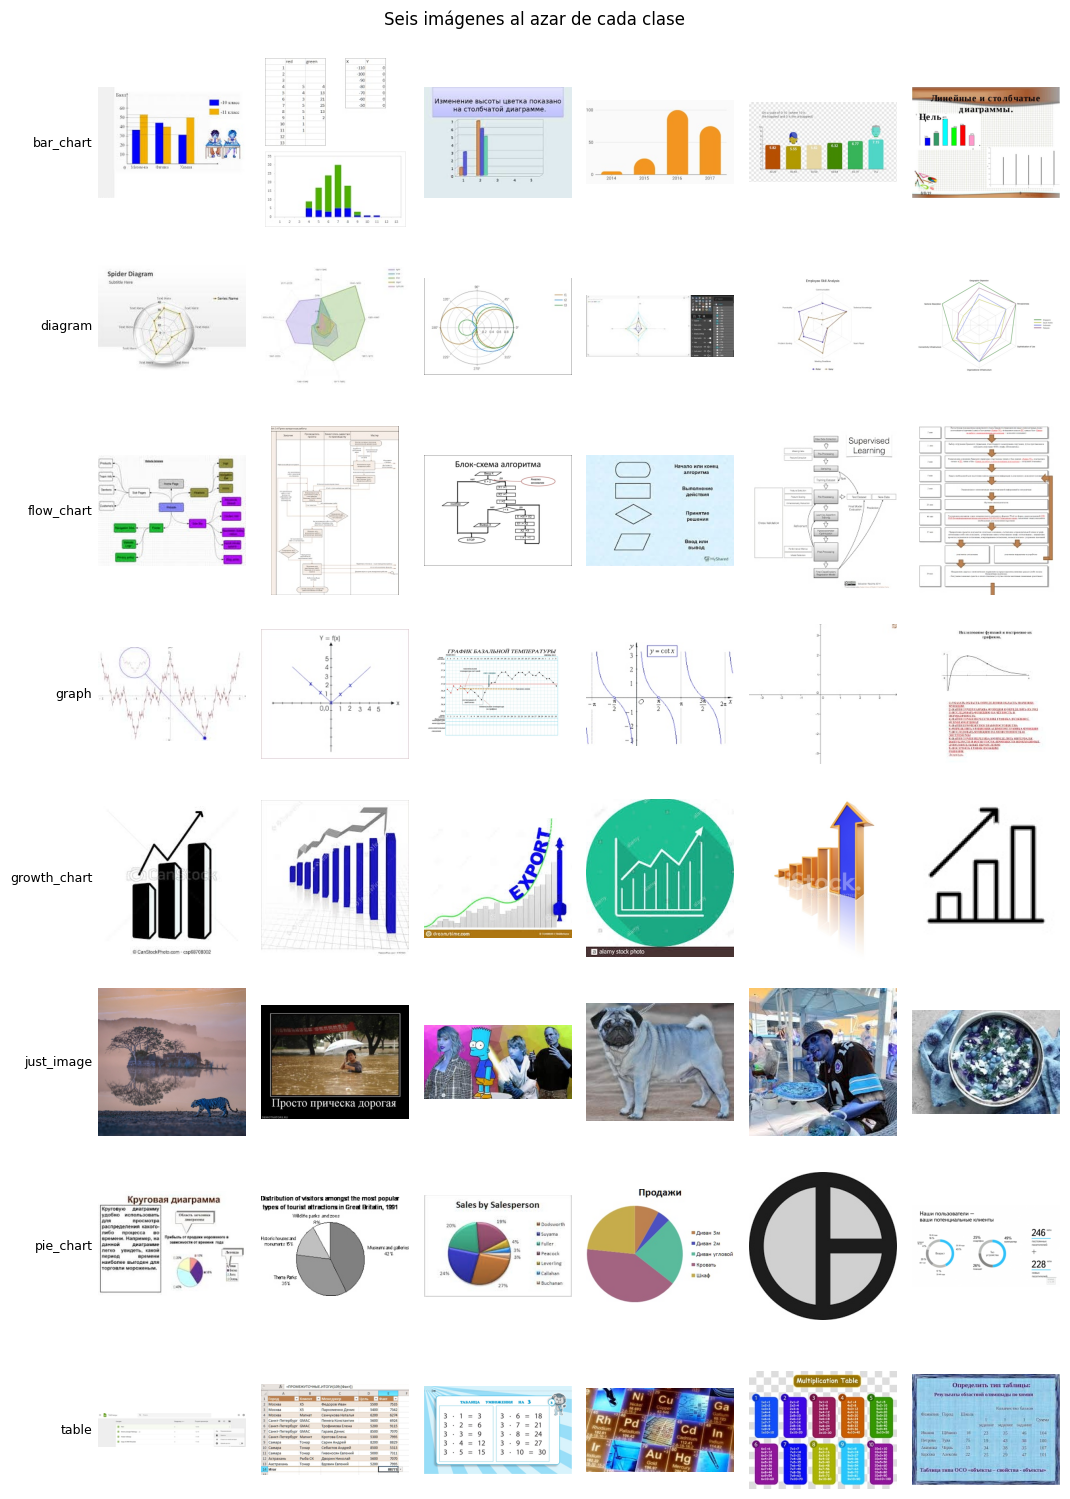

In [ ]:
def a_rgb(im, fondo=(255, 255, 255)):
    if getattr(im, 'n_frames', 1) > 1:
        im.seek(0)                      # en GIF animados se usa el primer fotograma
    if im.mode in ('RGBA', 'LA', 'PA') or (im.mode == 'P' and 'transparency' in im.info):
        im = im.convert('RGBA')
        lienzo = Image.new('RGBA', im.size, fondo + (255,))
        im = Image.alpha_composite(lienzo, im)
    return im.convert('RGB')


def limpiar_ejes(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for borde in ax.spines.values():
        borde.set_visible(False)


def mostrar(ax, ruta, titulo=None, color=None):
    with Image.open(ruta) as im:
        ax.imshow(a_rgb(im))
    limpiar_ejes(ax)
    if titulo:
        ax.set_title(titulo, fontsize=8, color=color or '#0b0b0b')


rng = np.random.default_rng(SEED)
n = 6
fig, axs = plt.subplots(N_CLASES, n, figsize=(n * 1.8, N_CLASES * 1.9))
for i, c in enumerate(CLASES):
    rutas = ok[ok.clase == c].ruta.values
    elegidas = rng.choice(rutas, size=min(n, len(rutas)), replace=False)
    for j in range(n):
        axs[i, j].axis('off')
        if j < len(elegidas):
            axs[i, j].axis('on')
            mostrar(axs[i, j], elegidas[j])
    axs[i, 0].set_ylabel(c, rotation=0, ha='right', va='center', fontsize=9)
    axs[i, 0].axis('on')
plt.suptitle('Seis imágenes al azar de cada clase', y=1.0)
plt.tight_layout()
plt.show()

*Conclusiones de la inspección.* El conjunto tiene 15.875 imágenes; todas se pueden abrir y todas tienen una clase reconocible. Las clases no están equilibradas: `just_image` reúne el 20 % de las imágenes (3.174) y `growth_chart` solo el 7,4 % (1.175), una relación de 2,7 a 1. Por eso se usan pesos de clase y el F1 macro como métrica principal.

Casi todos los ficheros son JPEG en RGB (15.773). Hay además 96 PNG, 3 GIF en paleta y un WEBP, que se leen igual gracias a la conversión a RGB. Los tamaños varían mucho: la mediana es de 275×205 píxeles, el 5 % más estrecho no llega a 170 píxeles de ancho y hay imágenes de más de 7.000. La diagonal descendente del diagrama de dispersión corresponde a miniaturas con el mismo número de píxeles y distinta forma, como las que generan los buscadores. La relación de aspecto se concentra en imágenes cuadradas y apaisadas, en torno a 4:3, pero hay bastantes muy alargadas. Por eso no se estiran al hacerlas cuadradas.

Hay 1.036 ficheros con contenido repetido en 496 grupos, y uno de esos grupos tiene etiquetas distintas. En los ejemplos se ve que algunas clases se solapan. `growth_chart` son sobre todo dibujos de barras con una flecha de subida, muy parecidos a `bar_chart`, y `diagram` contiene casi solo gráficos de radar y polares. Muchas imágenes llevan texto en ruso o marcas de agua de bancos de imágenes.

## Acondicionamiento y preprocesamiento

Decisiones a partir de la inspección:

- Se descartan los ficheros ilegibles y los que no tienen una clase reconocible.
- Los repetidos se dejan una sola vez para que la misma imagen no aparezca en entrenamiento y en test. Si un mismo contenido tiene etiquetas distintas, se eliminan todas sus copias, porque no hay forma de saber cuál es la buena.
- Se eliminan las imágenes con el lado menor por debajo de 32 píxeles, que al ampliarse no conservan detalle útil.
- Todas las imágenes se convierten a RGB con fondo blanco, como se explicó arriba.
- Para llevarlas a tamaño cuadrado no se estiran: se escalan conservando la proporción y se rellenan con blanco hasta completar el cuadrado (*letterbox*). Estirar deforma justo lo que distingue a unas clases de otras (una tarta se vuelve elipse, las barras cambian de grosor), como se ve en la figura siguiente.
- Las imágenes limpias se guardan una vez en JPEG de 224×224. Así cada época lee ficheros pequeños y homogéneos en lugar de decodificar PNG y GIF de varios megapíxeles.

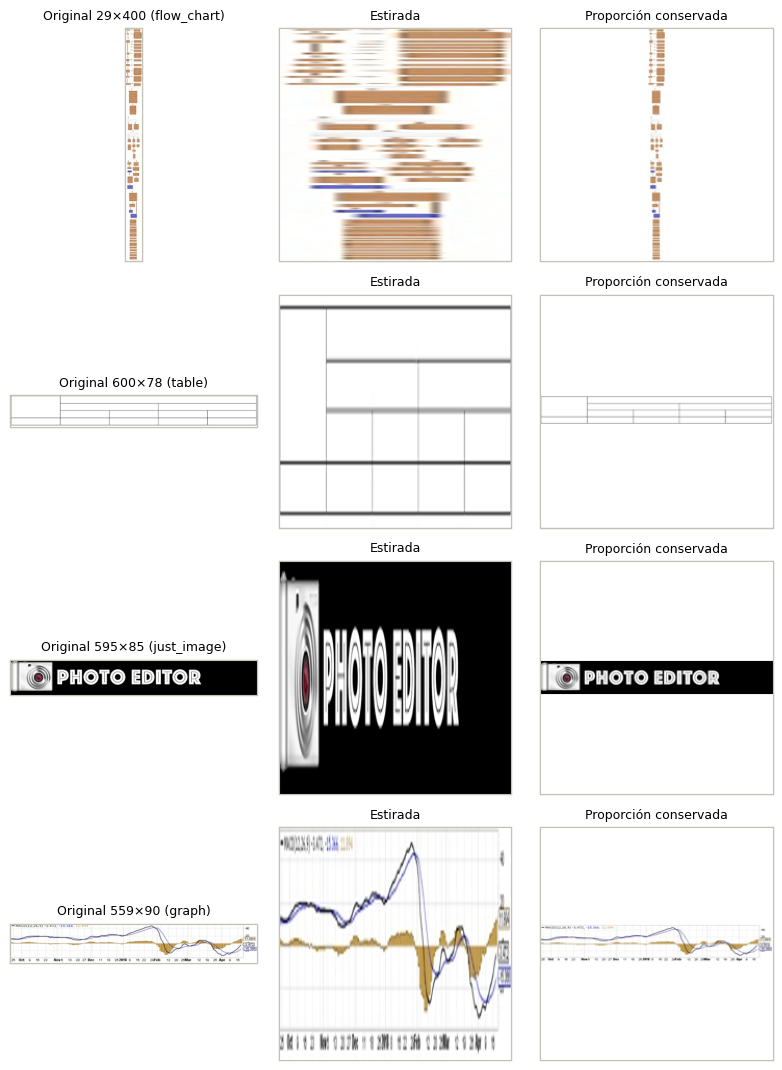

In [ ]:
def cuadrar(im, lado, fondo=(255, 255, 255)):
    escala = lado / max(im.size)
    nuevo = (max(1, round(im.width * escala)), max(1, round(im.height * escala)))
    im = im.resize(nuevo, Image.BICUBIC)
    lienzo = Image.new('RGB', (lado, lado), fondo)
    lienzo.paste(im, ((lado - nuevo[0]) // 2, (lado - nuevo[1]) // 2))
    return lienzo


# Comparación entre estirar y conservar la proporción en imágenes muy alargadas
alargadas = ok[ok.clase.notna()].assign(d=lambda d: np.abs(np.log(d.aspecto))).sort_values('d', ascending=False)
ejemplos = alargadas.groupby('clase').head(1).head(4)
fig, axs = plt.subplots(len(ejemplos), 3, figsize=(8, 2.7 * len(ejemplos)))
axs = np.atleast_2d(axs)
for fila, (_, r) in zip(axs, ejemplos.iterrows()):
    with Image.open(r.ruta) as im:
        im = a_rgb(im)
        for ax, img, titulo in zip(fila, [im, im.resize((TAM_GUARDADO, TAM_GUARDADO)), cuadrar(im, TAM_GUARDADO)],
                                   [f'Original {im.width}×{im.height} ({r.clase})', 'Estirada', 'Proporción conservada']):
            ax.imshow(img); ax.set_title(titulo, fontsize=9)
            limpiar_ejes(ax)
            ax.patch.set_edgecolor('#c3c2b7'); ax.patch.set_linewidth(1)
            for borde in ax.spines.values():
                borde.set_visible(True); borde.set_color('#c3c2b7')
plt.tight_layout()
plt.show()

In [ ]:
limpio = ok[ok.clase.notna()].copy()
pasos = [('Ficheros legibles con clase', len(limpio))]
limpio = limpio[~limpio.md5.isin(CONTRADICTORIOS)]
pasos.append(('Sin repetidos con etiqueta contradictoria', len(limpio)))
limpio = limpio.drop_duplicates('md5')
pasos.append(('Sin repetidos', len(limpio)))
limpio = limpio[limpio.lado_menor >= 32]
pasos.append(('Sin imágenes de menos de 32 px', len(limpio)))
display(pd.DataFrame(pasos, columns=['paso', 'imágenes']))

,paso,imágenes
0,Ficheros legibles con clase,15875
1,Sin repetidos con etiqueta contradictoria,15873
2,Sin repetidos,15334
3,Sin imágenes de menos de 32 px,15333


La partición es estratificada (70 % entrenamiento, 15 % validación y 15 % test), de modo que las tres conservan la proporción de clases. Validación se usa para comparar experimentos y tomar decisiones; test no se toca hasta la evaluación final. La partición se guarda en un CSV para poder reproducirla.

In [ ]:
idx_train, idx_resto = train_test_split(limpio.index, test_size=0.30, stratify=limpio.clase, random_state=SEED)
idx_val, idx_test = train_test_split(idx_resto, test_size=0.50, stratify=limpio.loc[idx_resto, 'clase'],
                                     random_state=SEED)
limpio['split'] = 'train'
limpio.loc[idx_val, 'split'] = 'val'
limpio.loc[idx_test, 'split'] = 'test'
limpio['y'] = limpio.clase.map({c: i for i, c in enumerate(CLASES)})

display(pd.crosstab(limpio.clase, limpio.split, margins=True, margins_name='total')[['train', 'val', 'test', 'total']])

split,train,val,test,total
clase,,,,
bar_chart,1348,289,289,1926
diagram,1194,256,256,1706
flow_chart,1176,252,252,1680
graph,1329,285,285,1899
growth_chart,776,166,166,1108
just_image,2208,473,473,3154
pie_chart,1271,272,272,1815
table,1431,307,307,2045
total,10733,2300,2300,15333


In [ ]:
PROCESADO = DATOS / f'procesado_{TAM_GUARDADO}'


def guardar_procesada(fila):
    destino = PROCESADO / fila.split / fila.clase / f'{fila.md5}.jpg'
    if not destino.exists():
        destino.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(fila.ruta) as im:
            cuadrar(a_rgb(im), TAM_GUARDADO).save(destino, quality=95)
    return str(destino)


t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    limpio['ruta_proc'] = list(ex.map(guardar_procesada, limpio.itertuples()))
limpio[['ruta', 'clase', 'split', 'md5']].to_csv(RESULTADOS / 'particion.csv', index=False)
print(f'{len(limpio)} imágenes procesadas en {time.time() - t0:.0f} s')

train_df = limpio[limpio.split == 'train']
val_df = limpio[limpio.split == 'val']
test_df = limpio[limpio.split == 'test']

15333 imágenes procesadas en 107 s


Pesos de clase. Si una clase tiene muchas más imágenes que otra, la red puede obtener buena *accuracy* ignorando las minoritarias. Cuando el desbalance supera 1,5 se ponderan las clases en la función de pérdida de forma inversamente proporcional a su frecuencia. Por la misma razón, además de la *accuracy* se usa el F1 macro (la media del F1 de cada clase, todas con el mismo peso) como métrica principal para comparar modelos.

In [ ]:
y_train = train_df.y.values
pesos = compute_class_weight('balanced', classes=np.arange(N_CLASES), y=y_train)
USAR_PESOS = DESBALANCE > 1.5
PESOS_CLASE = dict(enumerate(pesos)) if USAR_PESOS else None
print('Se usan pesos de clase:', USAR_PESOS)
display(pd.Series(pesos, index=CLASES, name='peso').round(2).to_frame().T)

Se usan pesos de clase: True


,bar_chart,diagram,flow_chart,graph,growth_chart,just_image,pie_chart,table
peso,1.0,1.12,1.14,1.01,1.73,0.61,1.06,0.94


Las imágenes se leen con `tf.data`. Las particiones a 128 píxeles se decodifican una vez y se guardan en memoria (`cache`) como enteros de 8 bits, que ocupan cuatro veces menos que en coma flotante. Las de 224 píxeles ocuparían más de 2 GB, así que se leen del disco en cada época: ya están guardadas a ese tamaño y decodificarlas es rápido. En ese caso se barajan las rutas de los ficheros antes de leerlos, para no tener todas las imágenes decodificadas en el búfer de mezcla. El conjunto de entrenamiento se baraja en cada época. Los valores de los píxeles se dejan en el rango 0-255 y cada modelo los normaliza en su primera capa, según lo que espere.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE


def leer_imagen(ruta, etiqueta, tam):
    img = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)
    img = tf.image.resize(img, (tam, tam), antialias=True)
    return tf.cast(tf.round(img), tf.uint8), etiqueta


def crear_dataset(datos, tam, batch, entrenamiento, en_memoria=True):
    ds = tf.data.Dataset.from_tensor_slices((datos.ruta_proc.values, datos.y.values.astype('int32')))
    if en_memoria:
        ds = ds.map(lambda r, e: leer_imagen(r, e, tam), num_parallel_calls=AUTOTUNE).cache()
        if entrenamiento:
            ds = ds.shuffle(len(datos), seed=SEED, reshuffle_each_iteration=True)
    else:
        # Se barajan las rutas, no las imágenes: el búfer de mezcla ocupa unos KB en lugar de GB
        if entrenamiento:
            ds = ds.shuffle(len(datos), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda r, e: leer_imagen(r, e, tam), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


ds_train_s = crear_dataset(train_df, TAM_SCRATCH, BATCH_SCRATCH, True)
ds_val_s = crear_dataset(val_df, TAM_SCRATCH, BATCH_SCRATCH, False)
ds_test_s = crear_dataset(test_df, TAM_SCRATCH, BATCH_SCRATCH, False)

x, y = next(iter(ds_train_s))
print('Lote de entrenamiento:', x.shape, x.dtype, '| etiquetas:', y.shape, '| rango de píxeles:',
      float(tf.reduce_min(x)), '-', float(tf.reduce_max(x)))

Lote de entrenamiento: (64, 128, 128, 3) <dtype: 'float32'> | etiquetas: (64,) | rango de píxeles: 0.0 - 255.0


### Funciones comunes de entrenamiento y evaluación

Todos los experimentos pasan por las mismas funciones: se entrenan con Adam y entropía cruzada, se paran con *early stopping*, se guardan el modelo y su historial, se dibujan las curvas y se anota una fila en la tabla de resultados con la mejor época. La brecha es la diferencia entre la *accuracy* de entrenamiento y la de validación en esa época. La de entrenamiento se mide con *dropout* y aumento de datos activos, así que queda algo por debajo de la real.

La función `decidir` compara el F1 macro de validación de un experimento con el de la mejor configuración hasta el momento. Si mejora, el cambio se conserva; si no, se descarta. Así cada decisión de diseño queda respaldada por un resultado.

In [ ]:
resultados = {}
historias = {}


def liberar_memoria():
    # Cada modelo deja en memoria su grafo y sus funciones compiladas. Sin esto la RAM
    # crece con cada experimento hasta agotarse.
    keras.backend.clear_session()
    gc.collect()


def entrenables(modelo):
    return int(sum(np.prod(w.shape) for w in modelo.trainable_weights))


def compilar(modelo, lr):
    # jit_compile=False: la compilación XLA de cada modelo ocupa mucha RAM y aquí apenas acelera
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'], jit_compile=False)


def predecir(modelo, ds):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_pred = modelo.predict(ds, verbose=0).argmax(axis=1)
    return y_true, y_pred


def graficar_historia(h, titulo, cortes=()):
    epocas = np.arange(1, len(h['loss']) + 1)
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, metrica, nombre in zip(axs, ['loss', 'accuracy'], ['Pérdida', 'Accuracy']):
        ax.plot(epocas, h[metrica], color=COLORES[0], label='entrenamiento')
        ax.plot(epocas, h['val_' + metrica], color=COLORES[1], label='validación')
        for x_corte, etiqueta in cortes:
            ax.axvline(x_corte + 0.5, color='#52514e', linestyle='--', linewidth=1)
            ax.text(x_corte + 0.7, ax.get_ylim()[1], etiqueta, va='top', fontsize=8, color='#52514e')
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.set_xlabel('Época'); ax.set_title(f'{nombre} - {titulo}')
    axs[1].legend(frameon=False)
    plt.tight_layout()
    plt.show()


def entrenar(modelo, nombre, estrategia, descripcion, ds_tr, ds_va, epocas, paciencia, callbacks_extra=()):
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=paciencia, restore_best_weights=True),
                 keras.callbacks.CSVLogger(str(RESULTADOS / f'{nombre}.csv'))] + list(callbacks_extra)
    print(f'{nombre}: {modelo.count_params():,} parámetros, {entrenables(modelo):,} entrenables')
    t0 = time.time()
    # shuffle=False porque el barajado ya lo hace el tf.data de entrenamiento
    h = modelo.fit(ds_tr, validation_data=ds_va, epochs=epocas, class_weight=PESOS_CLASE,
                   callbacks=callbacks, shuffle=False, verbose=2).history
    minutos = (time.time() - t0) / 60
    h = {k: [float(v) for v in vals] for k, vals in h.items()}
    mejor = int(np.argmin(h['val_loss']))
    y_true, y_pred = predecir(modelo, ds_va)
    resultados[nombre] = dict(
        estrategia=estrategia, descripcion=descripcion, parametros=modelo.count_params(),
        entrenables=entrenables(modelo), epocas=len(h['loss']), mejor_epoca=mejor + 1,
        acc_train=h['accuracy'][mejor], acc_val=h['val_accuracy'][mejor],
        brecha=h['accuracy'][mejor] - h['val_accuracy'][mejor], loss_val=h['val_loss'][mejor],
        f1_val=f1_score(y_true, y_pred, average='macro'), minutos=minutos)
    historias[nombre] = h
    modelo.save(RESULTADOS / f'{nombre}.keras')
    with open(RESULTADOS / f'{nombre}_historia.json', 'w') as f:
        json.dump(h, f)
    graficar_historia(h, nombre)
    r = resultados[nombre]
    print(f"{nombre}: acc_val = {r['acc_val']:.3f} | F1 macro val = {r['f1_val']:.3f} | "
          f"brecha = {r['brecha']:+.3f} | mejor época {r['mejor_epoca']} de {r['epocas']} | {minutos:.1f} min")
    return h


def decidir(nuevo, actual):
    a, n = resultados[actual]['f1_val'], resultados[nuevo]['f1_val']
    print(f'F1 macro de validación: {actual} = {a:.3f}, {nuevo} = {n:.3f} (diferencia {n - a:+.3f})')
    if n > a:
        print(f'Se conserva el cambio: la referencia pasa a ser {nuevo}.')
        return True
    print(f'El cambio no mejora: la referencia sigue siendo {actual}.')
    return False


def tabla_resultados(estrategia=None):
    t = pd.DataFrame(resultados).T
    if estrategia:
        t = t[t.estrategia == estrategia]
    cols = ['descripcion', 'parametros', 'entrenables', 'epocas', 'mejor_epoca',
            'acc_train', 'acc_val', 'brecha', 'f1_val', 'minutos']
    t = t[cols].copy()
    for c in ['acc_train', 'acc_val', 'brecha', 'f1_val', 'minutos']:
        t[c] = t[c].astype(float).round(3)
    return t

## Estrategia 1: CNN entrenada desde cero

La red se construye con una función parametrizable para que cada experimento cambie solo una cosa respecto al anterior. Todos los experimentos comparten estos elementos:

- bloques convolucionales con filtros de 3×3, *padding* `same` y ReLU, seguidos de *max pooling* 2×2 que reduce a la mitad la resolución. Dos convoluciones 3×3 seguidas ven lo mismo que una de 5×5 con menos parámetros y una no linealidad más;
- el número de filtros se duplica en cada bloque mientras la resolución se reduce;
- una capa densa de 128 neuronas y la salida *softmax* de 8 clases (en `float32` para que la precisión mixta no afecte a la pérdida);
- Adam con tasa de aprendizaje 1e-3 y lotes de 64 imágenes.

Entre un experimento y otro se varían la profundidad, el tipo de capa final (*Flatten* o *Global Average Pooling*), la *batch normalization*, el *dropout*, la regularización L2, el aumento de datos y la gestión de la tasa de aprendizaje.

In [ ]:
def crear_aumento():
    # Transformaciones suaves que mantienen el significado de un gráfico. No se usan volteos:
    # invierten el texto y los ejes, y un gráfico de crecimiento volteado deja de serlo.
    # El relleno es blanco (255) porque es el fondo de casi todas las imágenes.
    return keras.Sequential([
        layers.RandomTranslation(0.08, 0.08, fill_mode='constant', fill_value=255.0),
        layers.RandomZoom(0.12, fill_mode='constant', fill_value=255.0),
        layers.RandomRotation(0.03, fill_mode='constant', fill_value=255.0),
        layers.RandomContrast(0.2),
    ], name='aumento')


def crear_cnn(nombre, filtros=(32, 64, 128), convs_por_bloque=1, cabeza='flatten', bn=False,
              dropout=0.0, l2=0.0, aumento=False):
    reg = regularizers.l2(l2) if l2 else None
    entrada = keras.Input((TAM_SCRATCH, TAM_SCRATCH, 3))
    x = crear_aumento()(entrada) if aumento else entrada
    x = layers.Rescaling(1 / 255)(x)
    for f in filtros:
        for _ in range(convs_por_bloque):
            x = layers.Conv2D(f, 3, padding='same', use_bias=not bn, kernel_regularizer=reg)(x)
            if bn:
                x = layers.BatchNormalization()(x)
            x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x) if cabeza == 'flatten' else layers.GlobalAveragePooling2D()(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=reg)(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    salida = layers.Dense(N_CLASES, activation='softmax', dtype='float32')(x)
    return keras.Model(entrada, salida, name=nombre)


def experimento_cero(nombre, config, descripcion, epocas=EPOCAS_SCRATCH, lr=1e-3, callbacks_extra=()):
    liberar_memoria()
    keras.utils.set_random_seed(SEED)
    modelo = crear_cnn(nombre, **config)
    compilar(modelo, lr)
    return entrenar(modelo, nombre, 'desde cero', descripcion, ds_train_s, ds_val_s,
                    epocas, PACIENCIA_SCRATCH, callbacks_extra)

### Experimento S1: modelo base

Tres bloques convolucionales (32, 64 y 128 filtros) con una convolución cada uno, *Flatten* y la capa densa, sin ninguna regularización. Es el punto de partida contra el que se mide el resto. Se espera que aprenda rápido el conjunto de entrenamiento y que sobreajuste pronto, porque el *Flatten* sobre un mapa de 16×16×128 conecta más de 32.000 valores con la capa densa y concentra millones de parámetros.

S1_base: 4,288,712 parámetros, 4,288,712 entrenables
Epoch 1/30
168/168 - 17s - 104ms/step - accuracy: 0.4596 - loss: 1.5154 - val_accuracy: 0.5426 - val_loss: 1.2183
Epoch 2/30
168/168 - 7s - 39ms/step - accuracy: 0.6443 - loss: 1.0622 - val_accuracy: 0.6878 - val_loss: 0.9167
Epoch 3/30
168/168 - 6s - 38ms/step - accuracy: 0.7466 - loss: 0.7751 - val_accuracy: 0.7339 - val_loss: 0.7971
Epoch 4/30
168/168 - 7s - 40ms/step - accuracy: 0.8212 - loss: 0.5500 - val_accuracy: 0.7439 - val_loss: 0.7905
Epoch 5/30
168/168 - 6s - 38ms/step - accuracy: 0.8692 - loss: 0.3940 - val_accuracy: 0.7765 - val_loss: 0.7694
Epoch 6/30
168/168 - 7s - 44ms/step - accuracy: 0.9138 - loss: 0.2719 - val_accuracy: 0.8004 - val_loss: 0.7608
Epoch 7/30
168/168 - 7s - 40ms/step - accuracy: 0.9385 - loss: 0.1870 - val_accuracy: 0.7978 - val_loss: 0.8656
Epoch 8/30
168/168 - 7s - 42ms/step - accuracy: 0.9595 - loss: 0.1305 - val_accuracy: 0.7822 - val_loss: 0.9730
Epoch 9/30
168/168 - 7s - 41ms/step - accuracy: 0

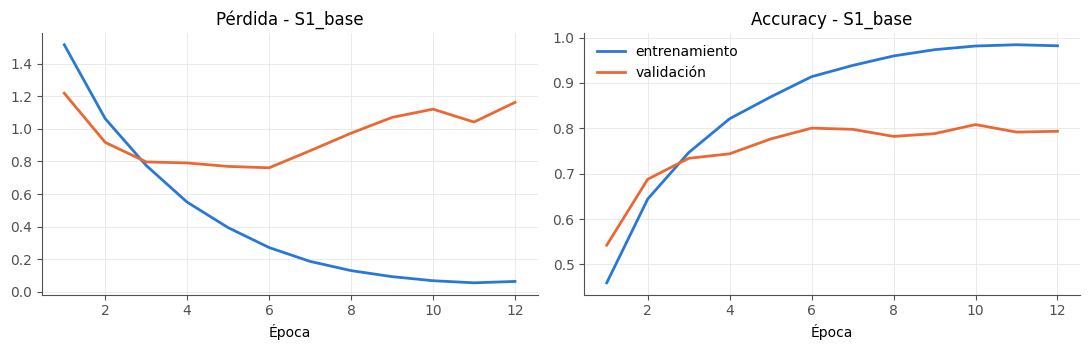

S1_base: acc_val = 0.800 | F1 macro val = 0.788 | brecha = +0.113 | mejor época 6 de 12 | 1.5 min


In [ ]:
config_s1 = dict(filtros=(32, 64, 128), convs_por_bloque=1, cabeza='flatten')
experimento_cero('S1_base', config_s1, '3 bloques, Flatten, sin regularización')
referencia, config_ref = 'S1_base', config_s1

*Análisis S1.* Las curvas se separan a partir de la época 3. Desde ahí la pérdida de entrenamiento baja hasta casi cero, mientras que la de validación toca su mínimo en la época 6 (0,76) y después sube. La *accuracy* de entrenamiento llega al 98 % y la de validación se queda en torno al 80 %; en la mejor época la brecha es de 0,113. El modelo sobreajusta pronto, como se esperaba con los más de 4 millones de parámetros que concentra el *Flatten*. El F1 macro de validación es 0,788.

### Experimento S2: Global Average Pooling en lugar de Flatten

*Global Average Pooling* resume cada mapa de características en su valor medio. La capa densa pasa de recibir más de 32.000 entradas a recibir 128, y el número de parámetros cae mucho. La hipótesis es que esto reduce el sobreajuste de S1, aunque puede perder información espacial.

S2_gap: 110,792 parámetros, 110,792 entrenables
Epoch 1/30
168/168 - 8s - 46ms/step - accuracy: 0.3058 - loss: 1.8432 - val_accuracy: 0.3887 - val_loss: 1.5854
Epoch 2/30
168/168 - 7s - 39ms/step - accuracy: 0.4086 - loss: 1.6115 - val_accuracy: 0.4161 - val_loss: 1.5279
Epoch 3/30
168/168 - 6s - 37ms/step - accuracy: 0.4572 - loss: 1.4898 - val_accuracy: 0.4500 - val_loss: 1.4155
Epoch 4/30
168/168 - 7s - 39ms/step - accuracy: 0.4967 - loss: 1.4040 - val_accuracy: 0.5074 - val_loss: 1.3571
Epoch 5/30
168/168 - 6s - 37ms/step - accuracy: 0.5403 - loss: 1.3253 - val_accuracy: 0.5257 - val_loss: 1.2802
Epoch 6/30
168/168 - 7s - 39ms/step - accuracy: 0.5580 - loss: 1.2806 - val_accuracy: 0.5509 - val_loss: 1.2171
Epoch 7/30
168/168 - 6s - 37ms/step - accuracy: 0.5947 - loss: 1.1880 - val_accuracy: 0.6174 - val_loss: 1.1171
Epoch 8/30
168/168 - 7s - 39ms/step - accuracy: 0.6251 - loss: 1.1125 - val_accuracy: 0.6074 - val_loss: 1.1001
Epoch 9/30
168/168 - 10s - 59ms/step - accuracy: 0.6514 

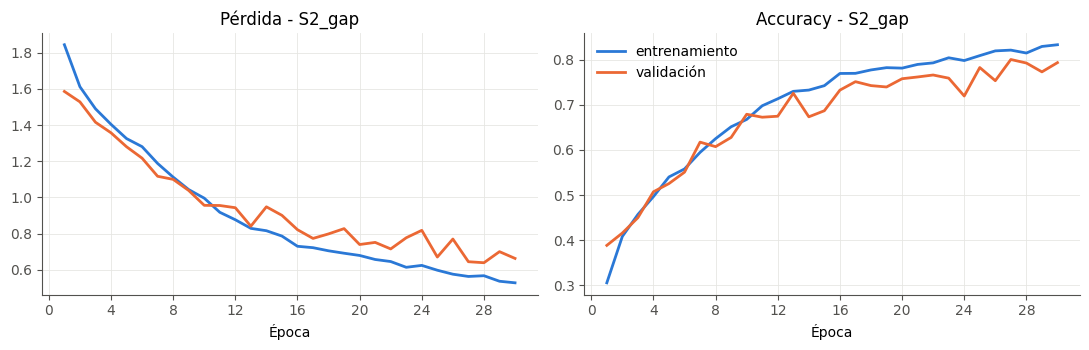

S2_gap: acc_val = 0.793 | F1 macro val = 0.775 | brecha = +0.022 | mejor época 28 de 30 | 3.4 min
F1 macro de validación: S1_base = 0.788, S2_gap = 0.775 (diferencia -0.013)
El cambio no mejora: la referencia sigue siendo S1_base.


In [ ]:
config_s2 = {**config_ref, 'cabeza': 'gap'}
experimento_cero('S2_gap', config_s2, 'S1 con Global Average Pooling')
if decidir('S2_gap', referencia):
    referencia, config_ref = 'S2_gap', config_s2

*Análisis S2.* Con *Global Average Pooling* el modelo pasa de 4,3 millones de parámetros a 111.000 y la brecha cae de 0,113 a 0,022, así que el sobreajuste casi desaparece. El F1, en cambio, baja un poco (0,775 frente a 0,788). La mejor época es la 28 de 30: la red seguía aprendiendo cuando se acabaron las épocas, porque con tan pocos parámetros aprende más despacio. Se mantiene el *Flatten*.

### Experimento S3: más profundidad

Cuatro bloques (32, 64, 128 y 256 filtros) con dos convoluciones cada uno. Más capas permiten combinar patrones simples (bordes, líneas) en formas más complejas (sectores de una tarta, celdas de una tabla, flechas de un diagrama de flujo), y el campo receptivo final cubre toda la imagen.

S3_profunda: 3,270,568 parámetros, 3,270,568 entrenables
Epoch 1/30
168/168 - 31s - 182ms/step - accuracy: 0.2947 - loss: 1.8421 - val_accuracy: 0.4217 - val_loss: 1.6060
Epoch 2/30
168/168 - 18s - 105ms/step - accuracy: 0.5217 - loss: 1.3520 - val_accuracy: 0.5657 - val_loss: 1.2720
Epoch 3/30
168/168 - 18s - 105ms/step - accuracy: 0.6508 - loss: 1.0494 - val_accuracy: 0.6774 - val_loss: 0.9522
Epoch 4/30
168/168 - 17s - 103ms/step - accuracy: 0.7184 - loss: 0.8513 - val_accuracy: 0.7148 - val_loss: 0.8436
Epoch 5/30
168/168 - 17s - 104ms/step - accuracy: 0.7854 - loss: 0.6568 - val_accuracy: 0.7391 - val_loss: 0.8314
Epoch 6/30
168/168 - 17s - 103ms/step - accuracy: 0.8196 - loss: 0.5383 - val_accuracy: 0.7548 - val_loss: 0.7994
Epoch 7/30
168/168 - 18s - 105ms/step - accuracy: 0.8582 - loss: 0.4235 - val_accuracy: 0.7687 - val_loss: 0.7936
Epoch 8/30
168/168 - 17s - 103ms/step - accuracy: 0.8943 - loss: 0.3163 - val_accuracy: 0.7835 - val_loss: 0.8689
Epoch 9/30
168/168 - 18s - 106m

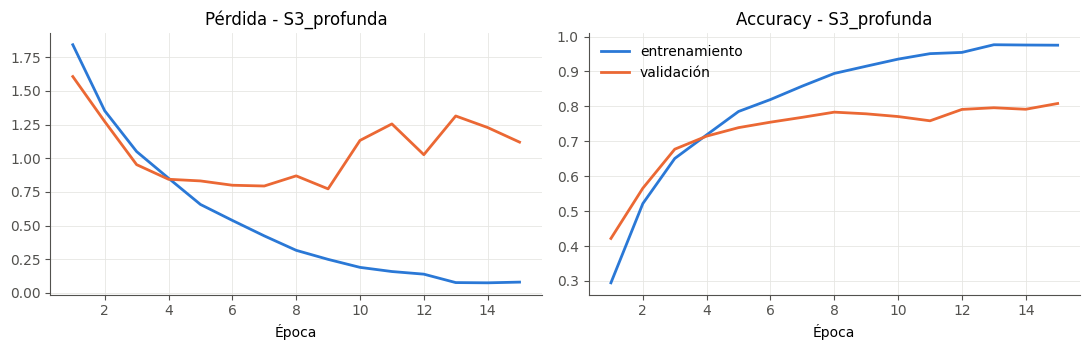

S3_profunda: acc_val = 0.779 | F1 macro val = 0.765 | brecha = +0.136 | mejor época 9 de 15 | 4.6 min
F1 macro de validación: S1_base = 0.788, S3_profunda = 0.765 (diferencia -0.023)
El cambio no mejora: la referencia sigue siendo S1_base.


In [ ]:
config_s3 = {**config_ref, 'filtros': (32, 64, 128, 256), 'convs_por_bloque': 2}
experimento_cero('S3_profunda', config_s3, '4 bloques de 2 convoluciones')
if decidir('S3_profunda', referencia):
    referencia, config_ref = 'S3_profunda', config_s3

*Análisis S3.* Más profundidad no ayuda. La *accuracy* de entrenamiento es la misma que en S1 (0,915), la de validación baja a 0,779 y la brecha sube a 0,136. La capacidad extra se usa para memorizar el entrenamiento y no se traduce en mejor validación. El experimento también tarda tres veces más (4,6 minutos).

### Experimento S4: batch normalization

*Batch normalization* normaliza la salida de cada convolución con la media y la varianza del lote. Estabiliza la distribución de las activaciones entre capas. Eso suele acelerar y suavizar el entrenamiento de redes más profundas, y el ruido de las estadísticas de cada lote añade algo de regularización.

S4_bn: 4,289,384 parámetros, 4,288,936 entrenables
Epoch 1/30
168/168 - 21s - 124ms/step - accuracy: 0.3652 - loss: 3.3969 - val_accuracy: 0.2735 - val_loss: 1.8747
Epoch 2/30
168/168 - 15s - 87ms/step - accuracy: 0.5045 - loss: 1.5232 - val_accuracy: 0.4900 - val_loss: 1.4685
Epoch 3/30
168/168 - 15s - 87ms/step - accuracy: 0.5770 - loss: 1.2866 - val_accuracy: 0.4122 - val_loss: 1.8064
Epoch 4/30
168/168 - 15s - 86ms/step - accuracy: 0.6163 - loss: 1.1675 - val_accuracy: 0.4470 - val_loss: 1.8956
Epoch 5/30
168/168 - 14s - 86ms/step - accuracy: 0.6850 - loss: 0.9776 - val_accuracy: 0.4078 - val_loss: 2.4681
Epoch 6/30
168/168 - 15s - 86ms/step - accuracy: 0.7224 - loss: 0.8671 - val_accuracy: 0.4139 - val_loss: 2.9561
Epoch 7/30
168/168 - 14s - 86ms/step - accuracy: 0.7616 - loss: 0.7499 - val_accuracy: 0.3296 - val_loss: 3.5040
Epoch 8/30
168/168 - 15s - 87ms/step - accuracy: 0.7896 - loss: 0.6581 - val_accuracy: 0.5422 - val_loss: 1.9009


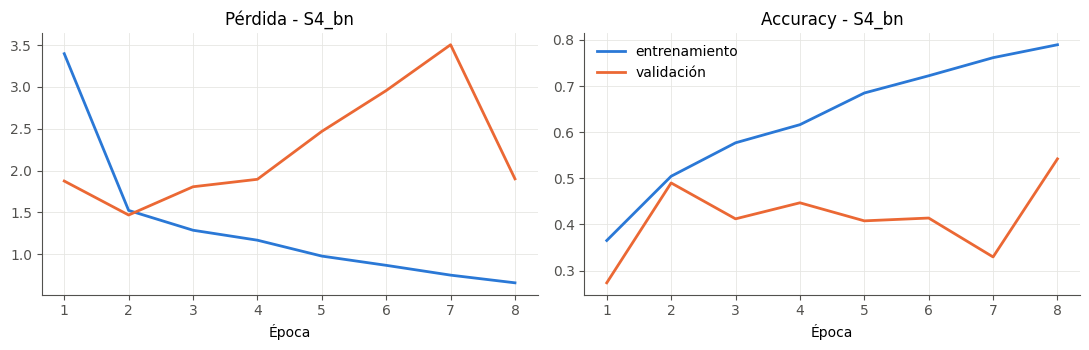

S4_bn: acc_val = 0.490 | F1 macro val = 0.417 | brecha = +0.015 | mejor época 2 de 8 | 2.0 min
F1 macro de validación: S1_base = 0.788, S4_bn = 0.417 (diferencia -0.372)
El cambio no mejora: la referencia sigue siendo S1_base.


In [ ]:
config_s4 = {**config_ref, 'bn': True}
experimento_cero('S4_bn', config_s4, 'referencia con batch normalization')
if decidir('S4_bn', referencia):
    referencia, config_ref = 'S4_bn', config_s4

*Análisis S4.* La *batch normalization* empeora mucho el resultado: el F1 cae a 0,417. La curva de validación es muy inestable, con la pérdida subiendo hasta 3,5 en la época 7 y la *accuracy* oscilando entre 0,27 y 0,54, mientras el entrenamiento avanza con normalidad. La mejor validación llega en la época 2 y el *early stopping* corta en la 8. Una explicación probable es que en validación la red usa las medias móviles de *batch normalization*, que con una tasa de 1e-3 van por detrás de unos pesos que cambian rápido; en entrenamiento usa las estadísticas de cada lote y no tiene ese problema. La subida de la última época (0,54) sugiere que con más paciencia podría haberse recuperado en parte, pero no se probó.

### Experimento S5: dropout y regularización L2

Se prueban dos técnicas contra el sobreajuste. El *dropout* (40 %) apaga neuronas al azar en la cabeza de la red durante el entrenamiento, así ninguna puede depender de otras concretas. La penalización L2 (1e-4) sobre los pesos de convoluciones y capas densas castiga los pesos grandes y favorece soluciones más suaves.

S5_dropout_l2: 4,288,712 parámetros, 4,288,712 entrenables
Epoch 1/30
168/168 - 9s - 55ms/step - accuracy: 0.4059 - loss: 1.6722 - val_accuracy: 0.5048 - val_loss: 1.3422
Epoch 2/30
168/168 - 7s - 41ms/step - accuracy: 0.5705 - loss: 1.3196 - val_accuracy: 0.5926 - val_loss: 1.2215
Epoch 3/30
168/168 - 7s - 43ms/step - accuracy: 0.6567 - loss: 1.0957 - val_accuracy: 0.7030 - val_loss: 0.9539
Epoch 4/30
168/168 - 7s - 41ms/step - accuracy: 0.7249 - loss: 0.9237 - val_accuracy: 0.7430 - val_loss: 0.8971
Epoch 5/30
168/168 - 7s - 44ms/step - accuracy: 0.7602 - loss: 0.8259 - val_accuracy: 0.7543 - val_loss: 0.8862
Epoch 6/30
168/168 - 11s - 63ms/step - accuracy: 0.8010 - loss: 0.7301 - val_accuracy: 0.7648 - val_loss: 0.8612
Epoch 7/30
168/168 - 7s - 41ms/step - accuracy: 0.8183 - loss: 0.6800 - val_accuracy: 0.7813 - val_loss: 0.8317
Epoch 8/30
168/168 - 7s - 43ms/step - accuracy: 0.8474 - loss: 0.6222 - val_accuracy: 0.7891 - val_loss: 0.8549
Epoch 9/30
168/168 - 7s - 41ms/step - accura

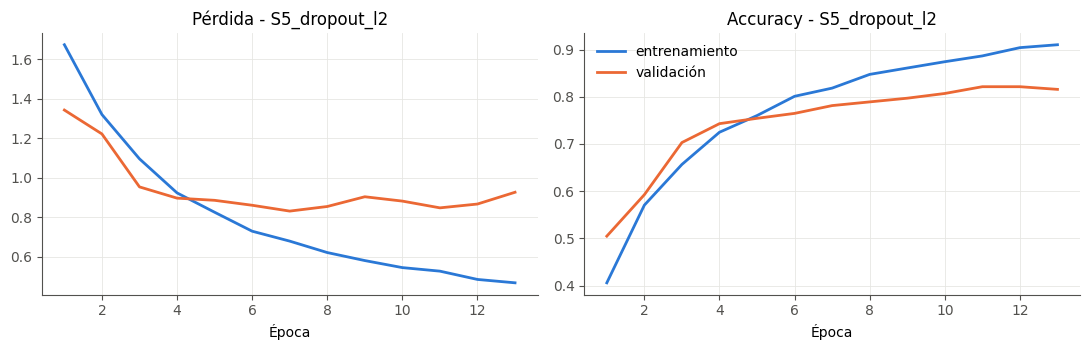

S5_dropout_l2: acc_val = 0.781 | F1 macro val = 0.769 | brecha = +0.037 | mejor época 7 de 13 | 1.7 min
F1 macro de validación: S1_base = 0.788, S5_dropout_l2 = 0.769 (diferencia -0.020)
El cambio no mejora: la referencia sigue siendo S1_base.


In [ ]:
config_s5 = {**config_ref, 'dropout': 0.4, 'l2': 1e-4}
experimento_cero('S5_dropout_l2', config_s5, 'referencia con dropout 0.4 y L2 1e-4')
if decidir('S5_dropout_l2', referencia):
    referencia, config_ref = 'S5_dropout_l2', config_s5

*Análisis S5.* *Dropout* y L2 reducen el sobreajuste: la brecha baja de 0,113 a 0,037. Lo consiguen sobre todo empeorando el entrenamiento (0,818 frente a 0,914), y la validación no mejora (F1 de 0,769 frente a 0,788). La red pierde capacidad de ajuste sin ganar generalización, así que el cambio se descarta y la referencia sigue siendo S1.

### Experimento S6: aumento de datos

El aumento de datos genera en cada época versiones ligeramente distintas de cada imagen de entrenamiento: desplazamientos, zoom, rotaciones de hasta unos 10 grados y cambios de contraste. La red ve más variedad sin necesidad de más imágenes y aprende que esos cambios no alteran la clase. Las transformaciones se eligieron para no cambiar el significado del gráfico (no se voltea). Como la tarea de entrenamiento se vuelve más difícil, se permiten hasta 50 épocas.

S6_aumento: 4,288,712 parámetros, 4,288,712 entrenables
Epoch 1/50
168/168 - 11s - 65ms/step - accuracy: 0.3630 - loss: 1.7374 - val_accuracy: 0.4474 - val_loss: 1.4077
Epoch 2/50
168/168 - 8s - 45ms/step - accuracy: 0.4986 - loss: 1.4008 - val_accuracy: 0.4830 - val_loss: 1.3032
Epoch 3/50
168/168 - 7s - 43ms/step - accuracy: 0.5450 - loss: 1.2886 - val_accuracy: 0.5835 - val_loss: 1.1626
Epoch 4/50
168/168 - 8s - 45ms/step - accuracy: 0.5987 - loss: 1.1681 - val_accuracy: 0.6504 - val_loss: 1.0532
Epoch 5/50
168/168 - 7s - 43ms/step - accuracy: 0.6500 - loss: 1.0294 - val_accuracy: 0.6622 - val_loss: 0.9939
Epoch 6/50
168/168 - 7s - 44ms/step - accuracy: 0.6948 - loss: 0.9181 - val_accuracy: 0.7109 - val_loss: 0.8730
Epoch 7/50
168/168 - 7s - 43ms/step - accuracy: 0.7282 - loss: 0.8295 - val_accuracy: 0.7157 - val_loss: 0.8862
Epoch 8/50
168/168 - 7s - 44ms/step - accuracy: 0.7460 - loss: 0.7787 - val_accuracy: 0.7222 - val_loss: 0.9289
Epoch 9/50
168/168 - 8s - 46ms/step - accuracy:

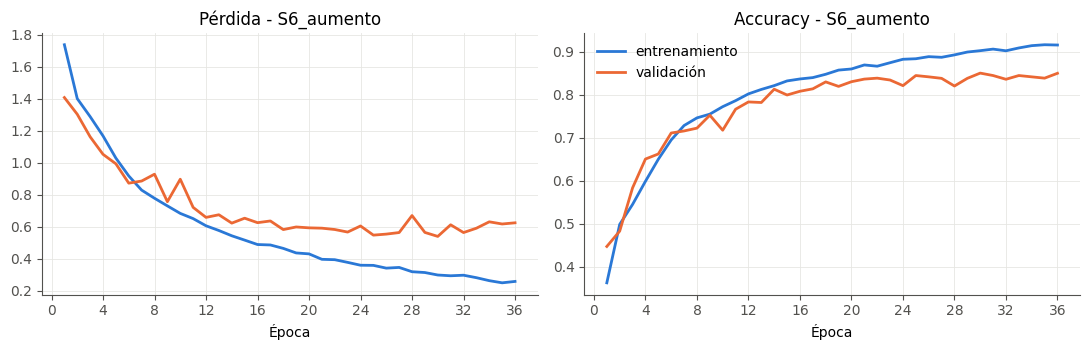

S6_aumento: acc_val = 0.850 | F1 macro val = 0.844 | brecha = +0.052 | mejor época 30 de 36 | 4.5 min
F1 macro de validación: S1_base = 0.788, S6_aumento = 0.844 (diferencia +0.056)
Se conserva el cambio: la referencia pasa a ser S6_aumento.


In [ ]:
config_s6 = {**config_ref, 'aumento': True}
experimento_cero('S6_aumento', config_s6, 'referencia con aumento de datos', epocas=EPOCAS_SCRATCH_LARGO)
if decidir('S6_aumento', referencia):
    referencia, config_ref = 'S6_aumento', config_s6

*Análisis S6.* El aumento de datos es el único cambio de la estrategia 1 que mejora la validación: el F1 sube de 0,788 a 0,844. Como S5 se descartó, S6 es S1 con aumento y sin *dropout*. La red necesita muchas más épocas (la mejor es la 30 de 36, frente a la 6 de S1), pero la pérdida de validación baja de forma sostenida hasta la época 25 aproximadamente, en lugar de subir a partir de la sexta. La brecha queda en 0,052.

### Experimento S7: reducción de la tasa de aprendizaje

Con una tasa fija de 1e-3, al final del entrenamiento los pasos pueden ser demasiado grandes para afinar el mínimo y la pérdida de validación oscila. `ReduceLROnPlateau` divide la tasa entre dos cada vez que la pérdida de validación lleva tres épocas sin mejorar, con un mínimo de 1e-5. La paciencia de este callback es menor que la del *early stopping* para que la tasa baje antes de que el entrenamiento se pare.

S7_reduce_lr: 4,288,712 parámetros, 4,288,712 entrenables
Epoch 1/50
168/168 - 9s - 55ms/step - accuracy: 0.4013 - loss: 1.6563 - val_accuracy: 0.4343 - val_loss: 1.4854 - learning_rate: 0.0010
Epoch 2/50
168/168 - 7s - 44ms/step - accuracy: 0.4945 - loss: 1.4068 - val_accuracy: 0.5400 - val_loss: 1.2601 - learning_rate: 0.0010
Epoch 3/50
168/168 - 7s - 43ms/step - accuracy: 0.5652 - loss: 1.2484 - val_accuracy: 0.6083 - val_loss: 1.1349 - learning_rate: 0.0010
Epoch 4/50
168/168 - 7s - 44ms/step - accuracy: 0.6230 - loss: 1.1071 - val_accuracy: 0.6643 - val_loss: 0.9862 - learning_rate: 0.0010
Epoch 5/50
168/168 - 7s - 44ms/step - accuracy: 0.6851 - loss: 0.9375 - val_accuracy: 0.6957 - val_loss: 0.9008 - learning_rate: 0.0010
Epoch 6/50
168/168 - 7s - 44ms/step - accuracy: 0.7121 - loss: 0.8616 - val_accuracy: 0.7091 - val_loss: 0.8502 - learning_rate: 0.0010
Epoch 7/50
168/168 - 7s - 43ms/step - accuracy: 0.7466 - loss: 0.7731 - val_accuracy: 0.7217 - val_loss: 0.8454 - learning_rat

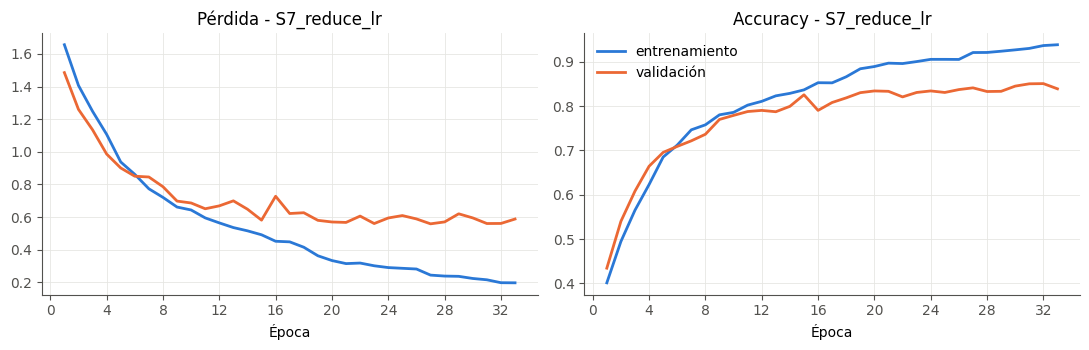

S7_reduce_lr: acc_val = 0.841 | F1 macro val = 0.834 | brecha = +0.080 | mejor época 27 de 33 | 4.1 min
F1 macro de validación: S6_aumento = 0.844, S7_reduce_lr = 0.834 (diferencia -0.010)
El cambio no mejora: la referencia sigue siendo S6_aumento.

Modelo desde cero seleccionado: S6_aumento


In [ ]:
reducir_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1)
experimento_cero('S7_reduce_lr', config_ref, 'referencia con ReduceLROnPlateau',
                 epocas=EPOCAS_SCRATCH_LARGO, callbacks_extra=[reducir_lr])
if decidir('S7_reduce_lr', referencia):
    referencia = 'S7_reduce_lr'
MEJOR_CERO = referencia
print('\nModelo desde cero seleccionado:', MEJOR_CERO)

### Resumen de la estrategia 1

In [ ]:
display(tabla_resultados('desde cero'))

,descripcion,parametros,entrenables,epocas,mejor_epoca,acc_train,acc_val,brecha,f1_val,minutos
S1_base,"3 bloques, Flatten, sin regularización",4288712,4288712,12,6,0.914,0.800,0.113,0.788,1.547
S2_gap,S1 con Global Average Pooling,110792,110792,30,28,0.815,0.793,0.022,0.775,3.377
S3_profunda,4 bloques de 2 convoluciones,3270568,3270568,15,9,0.915,0.779,0.136,0.765,4.612
S4_bn,referencia con batch normalization,4289384,4288936,8,2,0.505,0.490,0.015,0.417,2.047
S5_dropout_l2,referencia con dropout 0.4 y L2 1e-4,4288712,4288712,13,7,0.818,0.781,0.037,0.769,1.674
S6_aumento,referencia con aumento de datos,4288712,4288712,36,30,0.902,0.850,0.052,0.844,4.454
S7_reduce_lr,referencia con ReduceLROnPlateau,4288712,4288712,33,27,0.921,0.841,0.080,0.834,4.080


*Análisis de la estrategia 1.* De los seis cambios probados sobre S1 solo se conservó uno, el aumento de datos. El problema de la red desde cero es el sobreajuste, y cambiar la capacidad no lo resuelve: con menos parámetros (S2) aprende peor y con más (S3) memoriza más. *Dropout* y L2 (S5) reducen la brecha, pero también el ajuste. El aumento de datos funciona porque le da a la red más variedad de imágenes. *Batch normalization* (S4) volvió inestable la validación. Reducir la tasa de aprendizaje al estancarse (S7) dejó el F1 en 0,834; la diferencia con S6 es de 0,01, dentro de lo que puede variar entre dos ejecuciones, así que no puede decirse que empeore.

El modelo seleccionado, S6, tiene un F1 de 0,844 en validación y una brecha de 0,052. Sobreajusta algo, mucho menos que S1. No muestra subajuste, porque en entrenamiento llega al 90 %. Los siete experimentos tardaron 22 minutos en total.

## Estrategia 2: redes preentrenadas en ImageNet

Se comparan dos arquitecturas muy distintas:

- MobileNetV2 (unos 2,3 millones de parámetros en la base convolucional): pensada para móviles, con convoluciones separables en profundidad. Es rápida y ligera.
- ResNet50V2 (unos 23,6 millones): red residual profunda, con conexiones que suman la entrada de cada bloque a su salida y permiten entrenar muchas capas.

Las dos esperan los píxeles en el rango [-1, 1], de modo que la primera capa del modelo hace esa normalización.

El proceso para cada arquitectura tiene tres fases:

1. Transfer learning (TL): la base se congela y solo se entrena una cabeza nueva (*Global Average Pooling*, *dropout* del 30 % y *softmax*) con tasa 1e-3. La red usa las características que aprendió en ImageNet.
2. Fine-tuning 1 (FT1): se descongela el último tramo de la base y se sigue entrenando con una tasa 100 veces menor (1e-5), para ajustar sus pesos al problema sin destruir lo aprendido.
3. Fine-tuning 2 (FT2): se descongela un tramo más, también con tasa 1e-5, partiendo del resultado de FT1.

Las capas de *batch normalization* de la base se mantienen congeladas y en modo inferencia durante el *fine-tuning*. Con lotes de 32 imágenes sus estadísticas serían ruidosas y estropearían las de ImageNet.

In [ ]:
ds_train_p = crear_dataset(train_df, TAM_PRE, BATCH_PRE, True, en_memoria=False)
ds_val_p = crear_dataset(val_df, TAM_PRE, BATCH_PRE, False, en_memoria=False)
ds_test_p = crear_dataset(test_df, TAM_PRE, BATCH_PRE, False, en_memoria=False)

ARQUITECTURAS = {
    # arquitectura: (constructor, capa desde la que se descongela en FT1, en FT2)
    'MobileNetV2': (keras.applications.MobileNetV2, 'block_14_expand', 'block_11_expand'),
    'ResNet50V2': (keras.applications.ResNet50V2, 'conv5_block1_preact_bn', 'conv4_block1_preact_bn'),
}
bases = {}


def crear_preentrenado(arquitectura, aumento):
    keras.utils.set_random_seed(SEED)
    constructor = ARQUITECTURAS[arquitectura][0]
    with contextlib.redirect_stdout(io.StringIO()):     # oculta la barra de descarga de los pesos
        base = constructor(include_top=False, weights='imagenet', input_shape=(TAM_PRE, TAM_PRE, 3))
    base.trainable = False
    entrada = keras.Input((TAM_PRE, TAM_PRE, 3))
    x = crear_aumento()(entrada) if aumento else entrada
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)
    x = base(x, training=False)          # BN de la base siempre en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(N_CLASES, activation='softmax', dtype='float32')(x)
    return keras.Model(entrada, salida, name=arquitectura), base


def descongelar(base, desde_capa):
    nombres = [c.name for c in base.layers]
    corte = nombres.index(desde_capa)
    base.trainable = True
    for i, capa in enumerate(base.layers):
        capa.trainable = i >= corte and not isinstance(capa, layers.BatchNormalization)
    n = sum(1 for c in base.layers[corte:] if c.weights)
    print(f'Descongelado desde {desde_capa} (capa {corte} de {len(base.layers)}, {n} capas con pesos en el tramo)')


def transfer_learning(nombre, arquitectura, aumento, descripcion):
    liberar_memoria()
    modelo, base = crear_preentrenado(arquitectura, aumento)
    bases[nombre] = base
    compilar(modelo, 1e-3)
    entrenar(modelo, nombre, 'preentrenada', descripcion, ds_train_p, ds_val_p, EPOCAS_TL, PACIENCIA_PRE)
    return modelo


def fine_tuning(modelo, base, nombre, desde_capa, descripcion):
    descongelar(base, desde_capa)
    compilar(modelo, 1e-5)      # recompilar es necesario para que cuenten las capas descongeladas
    entrenar(modelo, nombre, 'preentrenada', descripcion, ds_train_p, ds_val_p, EPOCAS_FT, PACIENCIA_PRE)
    return modelo


def graficar_fases(nombres, titulo):
    h = {k: sum((historias[n][k] for n in nombres), []) for k in ['loss', 'val_loss', 'accuracy', 'val_accuracy']}
    cortes, acumulado = [], 0
    for n in nombres[:-1]:
        acumulado += len(historias[n]['loss'])
        cortes.append((acumulado, nombres[nombres.index(n) + 1].split('_')[-1]))
    graficar_historia(h, titulo, cortes)

### MobileNetV2: transfer learning con y sin aumento de datos

Antes de afinar se comprueba si el aumento de datos también ayuda con la base congelada. El resultado decide si se usa en el resto de experimentos con redes preentrenadas, incluidos los de ResNet50V2.

M1_MobileNetV2_TL: 2,268,232 parámetros, 10,248 entrenables
Epoch 1/15
336/336 - 44s - 130ms/step - accuracy: 0.8076 - loss: 0.6183 - val_accuracy: 0.8870 - val_loss: 0.3565
Epoch 2/15
336/336 - 36s - 107ms/step - accuracy: 0.8938 - loss: 0.3465 - val_accuracy: 0.8943 - val_loss: 0.3057
Epoch 3/15
336/336 - 34s - 103ms/step - accuracy: 0.9097 - loss: 0.2963 - val_accuracy: 0.9039 - val_loss: 0.2947
Epoch 4/15
336/336 - 41s - 121ms/step - accuracy: 0.9168 - loss: 0.2680 - val_accuracy: 0.9043 - val_loss: 0.2885
Epoch 5/15
336/336 - 36s - 108ms/step - accuracy: 0.9251 - loss: 0.2420 - val_accuracy: 0.9061 - val_loss: 0.2886
Epoch 6/15
336/336 - 34s - 100ms/step - accuracy: 0.9294 - loss: 0.2294 - val_accuracy: 0.9070 - val_loss: 0.2774
Epoch 7/15
336/336 - 46s - 137ms/step - accuracy: 0.9305 - loss: 0.2243 - val_accuracy: 0.9157 - val_loss: 0.2593
Epoch 8/15
336/336 - 37s - 109ms/step - accuracy: 0.9352 - loss: 0.2050 - val_accuracy: 0.9148 - val_loss: 0.2660
Epoch 9/15
336/336 - 41s - 1

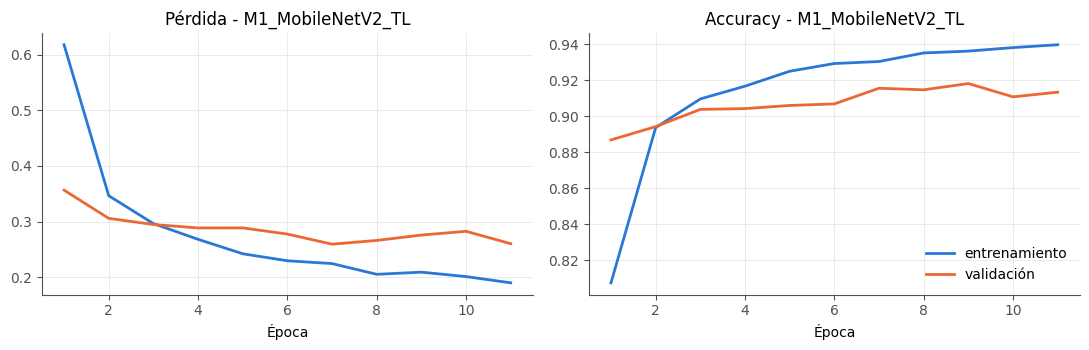

M1_MobileNetV2_TL: acc_val = 0.916 | F1 macro val = 0.905 | brecha = +0.015 | mejor época 7 de 11 | 7.0 min


In [ ]:
transfer_learning('M1_MobileNetV2_TL', 'MobileNetV2', False, 'base congelada, sin aumento');

M2_MobileNetV2_TL_aum: 2,268,232 parámetros, 10,248 entrenables
Epoch 1/15
336/336 - 41s - 123ms/step - accuracy: 0.7871 - loss: 0.6916 - val_accuracy: 0.8826 - val_loss: 0.3695
Epoch 2/15
336/336 - 35s - 105ms/step - accuracy: 0.8755 - loss: 0.4108 - val_accuracy: 0.8857 - val_loss: 0.3447
Epoch 3/15
336/336 - 34s - 102ms/step - accuracy: 0.8874 - loss: 0.3585 - val_accuracy: 0.8813 - val_loss: 0.3487
Epoch 4/15
336/336 - 34s - 100ms/step - accuracy: 0.8947 - loss: 0.3359 - val_accuracy: 0.8957 - val_loss: 0.3109
Epoch 5/15
336/336 - 41s - 122ms/step - accuracy: 0.9006 - loss: 0.3118 - val_accuracy: 0.8970 - val_loss: 0.3073
Epoch 6/15
336/336 - 41s - 122ms/step - accuracy: 0.9088 - loss: 0.2970 - val_accuracy: 0.8939 - val_loss: 0.3228
Epoch 7/15
336/336 - 39s - 115ms/step - accuracy: 0.9067 - loss: 0.2919 - val_accuracy: 0.8909 - val_loss: 0.3205
Epoch 8/15
336/336 - 33s - 99ms/step - accuracy: 0.9090 - loss: 0.2849 - val_accuracy: 0.8983 - val_loss: 0.3081
Epoch 9/15
336/336 - 35s 

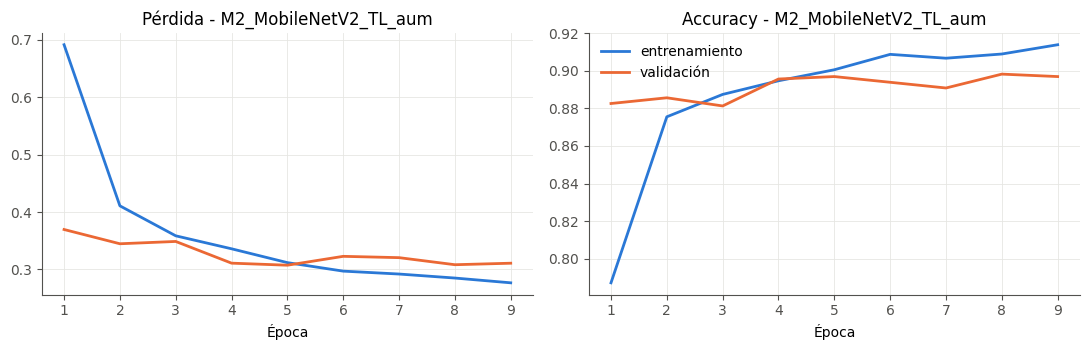

M2_MobileNetV2_TL_aum: acc_val = 0.897 | F1 macro val = 0.886 | brecha = +0.004 | mejor época 5 de 9 | 5.5 min
F1 macro de validación: M1_MobileNetV2_TL = 0.905, M2_MobileNetV2_TL_aum = 0.886 (diferencia -0.019)
El cambio no mejora: la referencia sigue siendo M1_MobileNetV2_TL.


In [ ]:
modelo_m2 = transfer_learning('M2_MobileNetV2_TL_aum', 'MobileNetV2', True, 'base congelada, con aumento')
AUMENTO_PRE = decidir('M2_MobileNetV2_TL_aum', 'M1_MobileNetV2_TL')

*Análisis M1 y M2.* Con la base congelada y solo 10.248 parámetros entrenables, MobileNetV2 alcanza un F1 de 0,905, seis puntos por encima de la mejor red desde cero (0,844). Las fotos de ImageNet se parecen poco a un gráfico, pero las primeras capas de la red detectan bordes, líneas, curvas y texturas. Eso sirve igual para distinguir barras, sectores o celdas. La brecha es muy pequeña (0,015) porque con tan pocos parámetros libres la cabeza apenas puede memorizar. El aumento de datos aquí empeora el resultado (0,886): con la base congelada la red no puede adaptar sus características a las imágenes transformadas y solo recibe una entrada más ruidosa. Por eso el resto de experimentos con redes preentrenadas, también los de ResNet50V2, se hacen sin aumento.

### MobileNetV2: fine-tuning progresivo

FT1 descongela el último grupo de bloques (desde `block_14`, el tramo de 160 filtros) y la capa convolucional final. FT2 amplía el tramo hasta `block_11`.

Descongelado desde block_14_expand (capa 125 de 154, 20 capas con pesos en el tramo)
M3_MobileNetV2_FT1: 2,268,232 parámetros, 1,520,968 entrenables
Epoch 1/15
336/336 - 46s - 137ms/step - accuracy: 0.9431 - loss: 0.1883 - val_accuracy: 0.9139 - val_loss: 0.2617
Epoch 2/15
336/336 - 34s - 101ms/step - accuracy: 0.9535 - loss: 0.1552 - val_accuracy: 0.9235 - val_loss: 0.2247
Epoch 3/15
336/336 - 36s - 107ms/step - accuracy: 0.9611 - loss: 0.1246 - val_accuracy: 0.9278 - val_loss: 0.2191
Epoch 4/15
336/336 - 40s - 119ms/step - accuracy: 0.9678 - loss: 0.1057 - val_accuracy: 0.9330 - val_loss: 0.2151
Epoch 5/15
336/336 - 35s - 104ms/step - accuracy: 0.9742 - loss: 0.0871 - val_accuracy: 0.9352 - val_loss: 0.2118
Epoch 6/15
336/336 - 34s - 100ms/step - accuracy: 0.9779 - loss: 0.0796 - val_accuracy: 0.9352 - val_loss: 0.2027
Epoch 7/15
336/336 - 35s - 105ms/step - accuracy: 0.9826 - loss: 0.0613 - val_accuracy: 0.9313 - val_loss: 0.2143
Epoch 8/15
336/336 - 38s - 113ms/step - accuracy: 0.9

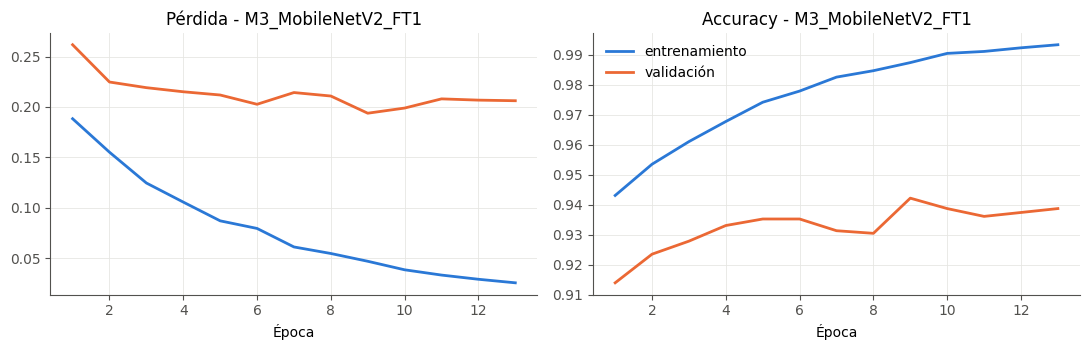

M3_MobileNetV2_FT1: acc_val = 0.942 | F1 macro val = 0.936 | brecha = +0.045 | mejor época 9 de 13 | 8.0 min


In [ ]:
if AUMENTO_PRE:
    nombre_tl, modelo_mnv = 'M2_MobileNetV2_TL_aum', modelo_m2
else:
    nombre_tl = 'M1_MobileNetV2_TL'
    modelo_mnv = keras.models.load_model(RESULTADOS / f'{nombre_tl}.keras')
    bases[nombre_tl] = next(c for c in modelo_mnv.layers if isinstance(c, keras.Model) and c.name != 'aumento')
base_mnv = bases[nombre_tl]
_, capa_ft1, capa_ft2 = ARQUITECTURAS['MobileNetV2']
fine_tuning(modelo_mnv, base_mnv, 'M3_MobileNetV2_FT1', capa_ft1, f'FT desde {capa_ft1}');

Descongelado desde block_11_expand (capa 98 de 154, 38 capas con pesos en el tramo)
M4_MobileNetV2_FT2: 2,268,232 parámetros, 1,905,160 entrenables
Epoch 1/15
336/336 - 50s - 148ms/step - accuracy: 0.9874 - loss: 0.0457 - val_accuracy: 0.9443 - val_loss: 0.1865
Epoch 2/15
336/336 - 41s - 121ms/step - accuracy: 0.9887 - loss: 0.0402 - val_accuracy: 0.9422 - val_loss: 0.1929
Epoch 3/15
336/336 - 37s - 110ms/step - accuracy: 0.9914 - loss: 0.0281 - val_accuracy: 0.9387 - val_loss: 0.1920
Epoch 4/15
336/336 - 36s - 108ms/step - accuracy: 0.9930 - loss: 0.0265 - val_accuracy: 0.9448 - val_loss: 0.1869
Epoch 5/15
336/336 - 42s - 125ms/step - accuracy: 0.9947 - loss: 0.0213 - val_accuracy: 0.9478 - val_loss: 0.1916


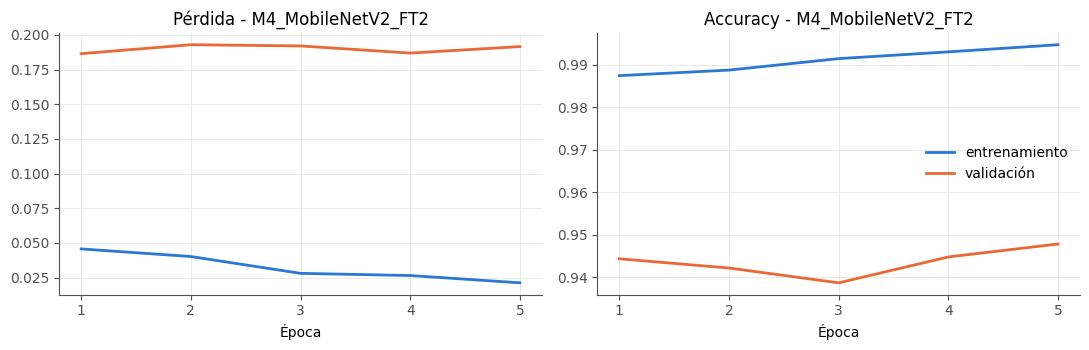

M4_MobileNetV2_FT2: acc_val = 0.944 | F1 macro val = 0.937 | brecha = +0.043 | mejor época 1 de 5 | 3.4 min


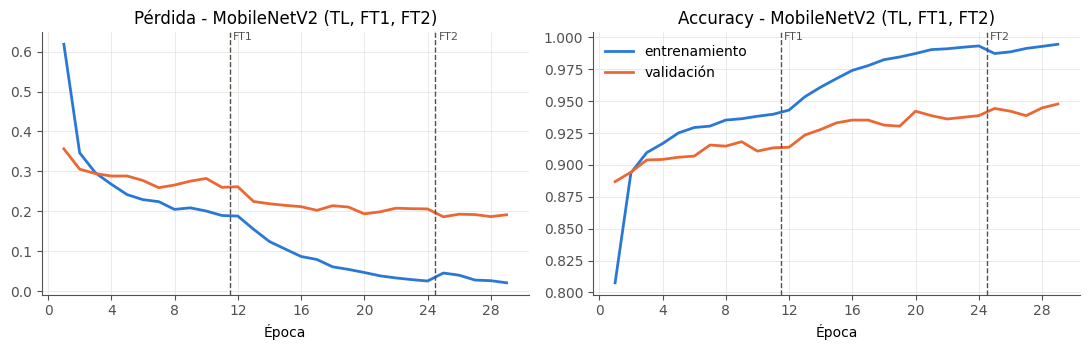

In [ ]:
fine_tuning(modelo_mnv, base_mnv, 'M4_MobileNetV2_FT2', capa_ft2, f'FT desde {capa_ft2}')
graficar_fases([nombre_tl, 'M3_MobileNetV2_FT1', 'M4_MobileNetV2_FT2'], 'MobileNetV2 (TL, FT1, FT2)')

*Análisis del fine-tuning de MobileNetV2.* Al descongelar el último tramo (FT1, 1,5 millones de parámetros entrenables) el F1 de validación sube de 0,905 a 0,936. En la figura se ve que al empezar FT1 la pérdida de entrenamiento cae de golpe y la de validación baja un escalón; la tasa de 1e-5 evita el salto hacia arriba que produciría una tasa alta al tocar pesos ya entrenados. La *accuracy* de entrenamiento sube hasta 0,99 y la brecha pasa de 0,015 a 0,045, así que parte de la mejora es ajuste al propio entrenamiento. FT2 casi no aporta: el F1 queda en 0,937, la mejor época es la primera de la fase y el *early stopping* la detiene en la quinta. Descongelar más capas de MobileNetV2 ya no compensa.

### ResNet50V2: transfer learning y fine-tuning progresivo

Se sigue el mismo procedimiento, con la decisión sobre el aumento de datos tomada con MobileNetV2. FT1 descongela el último bloque residual (`conv5`) y FT2 añade el penúltimo (`conv4`), que contiene la mayor parte de las capas de la red.

R1_ResNet50V2_TL: 23,581,192 parámetros, 16,392 entrenables
Epoch 1/15
336/336 - 71s - 212ms/step - accuracy: 0.8211 - loss: 0.5817 - val_accuracy: 0.8943 - val_loss: 0.3351
Epoch 2/15
336/336 - 55s - 163ms/step - accuracy: 0.9070 - loss: 0.3141 - val_accuracy: 0.9096 - val_loss: 0.2948
Epoch 3/15
336/336 - 55s - 164ms/step - accuracy: 0.9215 - loss: 0.2666 - val_accuracy: 0.9148 - val_loss: 0.2777
Epoch 4/15
336/336 - 55s - 165ms/step - accuracy: 0.9274 - loss: 0.2371 - val_accuracy: 0.9187 - val_loss: 0.2638
Epoch 5/15
336/336 - 55s - 164ms/step - accuracy: 0.9356 - loss: 0.2156 - val_accuracy: 0.9213 - val_loss: 0.2638
Epoch 6/15
336/336 - 55s - 164ms/step - accuracy: 0.9380 - loss: 0.2074 - val_accuracy: 0.9209 - val_loss: 0.2486
Epoch 7/15
336/336 - 56s - 166ms/step - accuracy: 0.9429 - loss: 0.1886 - val_accuracy: 0.9222 - val_loss: 0.2525
Epoch 8/15
336/336 - 84s - 249ms/step - accuracy: 0.9463 - loss: 0.1751 - val_accuracy: 0.9257 - val_loss: 0.2532
Epoch 9/15
336/336 - 54s - 1

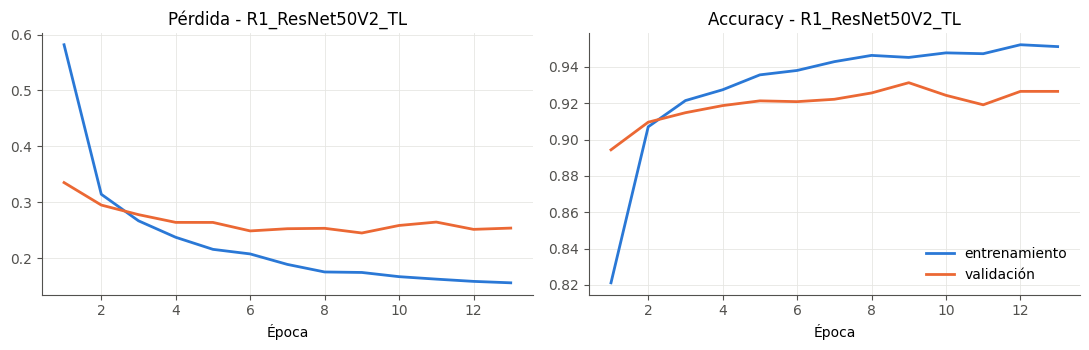

R1_ResNet50V2_TL: acc_val = 0.931 | F1 macro val = 0.923 | brecha = +0.014 | mejor época 9 de 13 | 13.2 min


In [ ]:
# Los modelos de MobileNetV2 ya están guardados en disco: se liberan antes de cargar ResNet50V2
del modelo_mnv, base_mnv, modelo_m2
bases.clear()
modelo_rn = transfer_learning('R1_ResNet50V2_TL', 'ResNet50V2', AUMENTO_PRE,
                              'base congelada' + (', con aumento' if AUMENTO_PRE else ', sin aumento'))

Descongelado desde conv5_block1_preact_bn (capa 154 de 190, 20 capas con pesos en el tramo)
R2_ResNet50V2_FT1: 23,581,192 parámetros, 14,966,792 entrenables
Epoch 1/15
336/336 - 84s - 249ms/step - accuracy: 0.9537 - loss: 0.1506 - val_accuracy: 0.9326 - val_loss: 0.2137
Epoch 2/15
336/336 - 72s - 214ms/step - accuracy: 0.9786 - loss: 0.0689 - val_accuracy: 0.9430 - val_loss: 0.2064
Epoch 3/15
336/336 - 71s - 211ms/step - accuracy: 0.9881 - loss: 0.0398 - val_accuracy: 0.9430 - val_loss: 0.2168
Epoch 4/15
336/336 - 71s - 211ms/step - accuracy: 0.9939 - loss: 0.0245 - val_accuracy: 0.9465 - val_loss: 0.2192
Epoch 5/15
336/336 - 71s - 212ms/step - accuracy: 0.9945 - loss: 0.0162 - val_accuracy: 0.9500 - val_loss: 0.2259
Epoch 6/15
336/336 - 71s - 211ms/step - accuracy: 0.9966 - loss: 0.0130 - val_accuracy: 0.9500 - val_loss: 0.2390


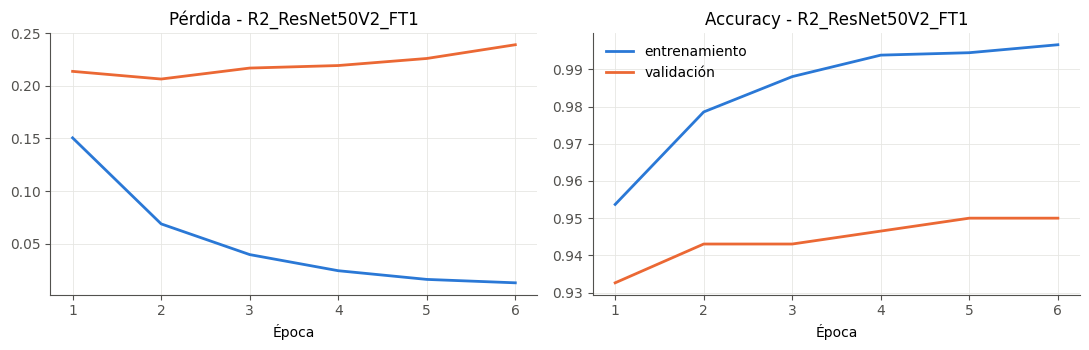

R2_ResNet50V2_FT1: acc_val = 0.943 | F1 macro val = 0.936 | brecha = +0.036 | mejor época 2 de 6 | 7.3 min


In [ ]:
base_rn = bases['R1_ResNet50V2_TL']
_, capa_ft1, capa_ft2 = ARQUITECTURAS['ResNet50V2']
fine_tuning(modelo_rn, base_rn, 'R2_ResNet50V2_FT1', capa_ft1, f'FT desde {capa_ft1}');

Descongelado desde conv4_block1_preact_bn (capa 86 de 190, 57 capas con pesos en el tramo)
R3_ResNet50V2_FT2: 23,581,192 parámetros, 22,051,848 entrenables
Epoch 1/15
336/336 - 109s - 324ms/step - accuracy: 0.9837 - loss: 0.0557 - val_accuracy: 0.9443 - val_loss: 0.2069
Epoch 2/15
336/336 - 93s - 277ms/step - accuracy: 0.9918 - loss: 0.0273 - val_accuracy: 0.9535 - val_loss: 0.1992
Epoch 3/15
336/336 - 92s - 275ms/step - accuracy: 0.9946 - loss: 0.0202 - val_accuracy: 0.9409 - val_loss: 0.2061
Epoch 4/15
336/336 - 93s - 277ms/step - accuracy: 0.9964 - loss: 0.0137 - val_accuracy: 0.9517 - val_loss: 0.2147
Epoch 5/15
336/336 - 92s - 274ms/step - accuracy: 0.9955 - loss: 0.0169 - val_accuracy: 0.9500 - val_loss: 0.2238
Epoch 6/15
336/336 - 93s - 276ms/step - accuracy: 0.9958 - loss: 0.0125 - val_accuracy: 0.9548 - val_loss: 0.1981
Epoch 7/15
336/336 - 92s - 274ms/step - accuracy: 0.9969 - loss: 0.0101 - val_accuracy: 0.9522 - val_loss: 0.2176
Epoch 8/15
336/336 - 92s - 275ms/step - accur

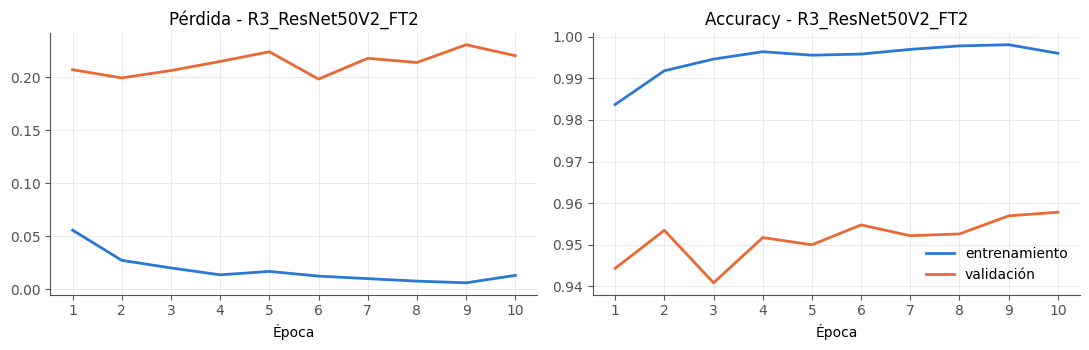

R3_ResNet50V2_FT2: acc_val = 0.955 | F1 macro val = 0.950 | brecha = +0.041 | mejor época 6 de 10 | 15.7 min


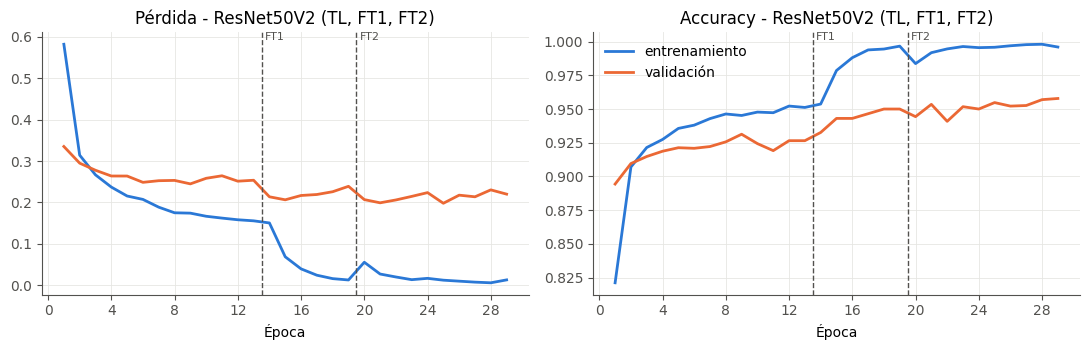

In [ ]:
fine_tuning(modelo_rn, base_rn, 'R3_ResNet50V2_FT2', capa_ft2, f'FT desde {capa_ft2}')
graficar_fases(['R1_ResNet50V2_TL', 'R2_ResNet50V2_FT1', 'R3_ResNet50V2_FT2'], 'ResNet50V2 (TL, FT1, FT2)')

*Análisis del transfer learning y el fine-tuning de ResNet50V2.* Con la base congelada, ResNet50V2 rinde más que MobileNetV2 (F1 de 0,923 frente a 0,905), probablemente porque sus 2.048 características por imagen describen los gráficos con más detalle que las 1.280 de MobileNetV2. En FT1, que descongela el bloque `conv5`, el F1 sube a 0,936, igual que en el FT1 de MobileNetV2, y la mejor época es la segunda. A diferencia de MobileNetV2, el segundo descongelado sí mejora: FT2, con 22 millones de parámetros entrenables, llega a 0,950, el mejor resultado de todos los experimentos. La *accuracy* de entrenamiento queda casi en 1 (0,996) y la brecha (0,041) es parecida a la de MobileNetV2. A cambio, las tres fases tardaron 36 minutos.

### Comparación de las arquitecturas preentrenadas

La elección se hace con el F1 macro de validación. El conjunto de test sigue sin usarse.

In [ ]:
tabla_pre = tabla_resultados('preentrenada')
display(tabla_pre)
f1 = tabla_pre.f1_val.astype(float)
MEJOR_MNV = f1[f1.index.str.contains('MobileNetV2')].idxmax()
MEJOR_RN = f1[f1.index.str.contains('ResNet50V2')].idxmax()
MEJOR_PRE = f1.idxmax()
print('Mejor MobileNetV2:', MEJOR_MNV, f'({f1[MEJOR_MNV]:.3f})')
print('Mejor ResNet50V2:', MEJOR_RN, f'({f1[MEJOR_RN]:.3f})')
print('Arquitectura preentrenada seleccionada:', MEJOR_PRE)

,descripcion,parametros,entrenables,epocas,mejor_epoca,acc_train,acc_val,brecha,f1_val,minutos
M1_MobileNetV2_TL,"base congelada, sin aumento",2268232,10248,11,7,0.930,0.916,0.015,0.905,7.047
M2_MobileNetV2_TL_aum,"base congelada, con aumento",2268232,10248,9,5,0.901,0.897,0.004,0.886,5.546
M3_MobileNetV2_FT1,FT desde block_14_expand,2268232,1520968,13,9,0.987,0.942,0.045,0.936,7.974
M4_MobileNetV2_FT2,FT desde block_11_expand,2268232,1905160,5,1,0.987,0.944,0.043,0.937,3.435
R1_ResNet50V2_TL,"base congelada, sin aumento",23581192,16392,13,9,0.945,0.931,0.014,0.923,13.178
R2_ResNet50V2_FT1,FT desde conv5_block1_preact_bn,23581192,14966792,6,2,0.979,0.943,0.036,0.936,7.329
R3_ResNet50V2_FT2,FT desde conv4_block1_preact_bn,23581192,22051848,10,6,0.996,0.955,0.041,0.950,15.693


Mejor MobileNetV2: M4_MobileNetV2_FT2 (0.937)
Mejor ResNet50V2: R3_ResNet50V2_FT2 (0.950)
Arquitectura preentrenada seleccionada: R3_ResNet50V2_FT2


*Análisis de la comparación entre arquitecturas.* Por F1 de validación gana ResNet50V2 (0,950 frente a 0,937 de MobileNetV2), y es la que se selecciona. La diferencia es de poco más de un punto y sale cara: ResNet50V2 tiene unas diez veces más parámetros (23,6 millones frente a 2,3) y sus tres fases tardaron 36 minutos, frente a 18 las de MobileNetV2. Si el modelo tuviera que funcionar en un equipo modesto o procesar muchas imágenes, MobileNetV2 sería la opción razonable.

## Evaluación y comparación de las estrategias

### Todos los experimentos en validación

,descripcion,parametros,entrenables,epocas,mejor_epoca,acc_train,acc_val,brecha,f1_val,minutos
S1_base,"3 bloques, Flatten, sin regularización",4288712,4288712,12,6,0.914,0.800,0.113,0.788,1.547
S2_gap,S1 con Global Average Pooling,110792,110792,30,28,0.815,0.793,0.022,0.775,3.377
S3_profunda,4 bloques de 2 convoluciones,3270568,3270568,15,9,0.915,0.779,0.136,0.765,4.612
S4_bn,referencia con batch normalization,4289384,4288936,8,2,0.505,0.490,0.015,0.417,2.047
S5_dropout_l2,referencia con dropout 0.4 y L2 1e-4,4288712,4288712,13,7,0.818,0.781,0.037,0.769,1.674
S6_aumento,referencia con aumento de datos,4288712,4288712,36,30,0.902,0.850,0.052,0.844,4.454
S7_reduce_lr,referencia con ReduceLROnPlateau,4288712,4288712,33,27,0.921,0.841,0.080,0.834,4.080
M1_MobileNetV2_TL,"base congelada, sin aumento",2268232,10248,11,7,0.930,0.916,0.015,0.905,7.047
M2_MobileNetV2_TL_aum,"base congelada, con aumento",2268232,10248,9,5,0.901,0.897,0.004,0.886,5.546
M3_MobileNetV2_FT1,FT desde block_14_expand,2268232,1520968,13,9,0.987,0.942,0.045,0.936,7.974


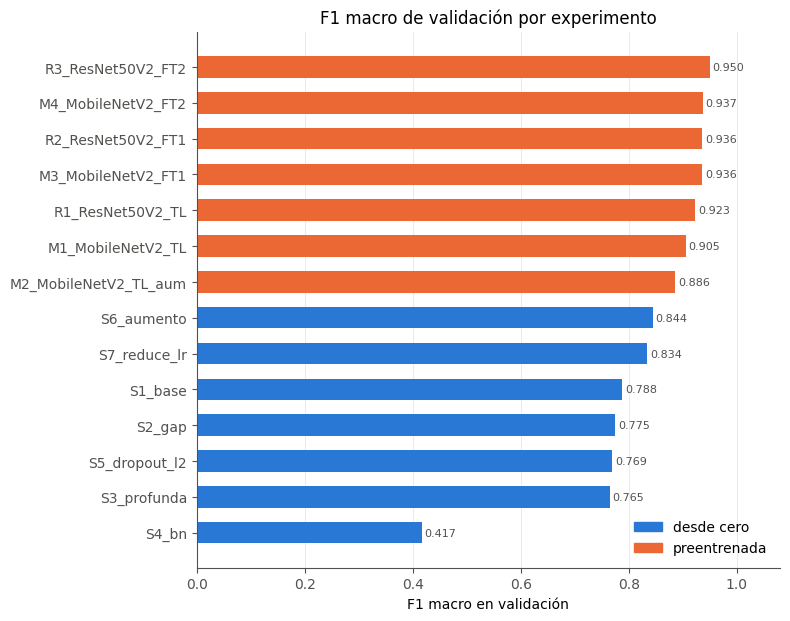

In [ ]:
tabla = tabla_resultados()
display(tabla)

orden = tabla.f1_val.astype(float).sort_values()
colores = [COLORES[0] if resultados[n]['estrategia'] == 'desde cero' else COLORES[1] for n in orden.index]
fig, ax = plt.subplots(figsize=(8, 0.38 * len(orden) + 1))
ax.barh(orden.index, orden.values, color=colores, height=0.6)
for i, v in enumerate(orden.values):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8, color='#52514e')
ax.set_xlabel('F1 macro en validación'); ax.set_xlim(0, 1.08)
ax.grid(axis='y', visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORES[0]), plt.Rectangle((0, 0), 1, 1, color=COLORES[1])],
          labels=['desde cero', 'preentrenada'], frameon=False, loc='lower right')
ax.set_title('F1 macro de validación por experimento')
plt.tight_layout()
plt.show()

### Rendimiento en test

Se evalúan en test el mejor modelo desde cero y el mejor de cada arquitectura preentrenada, cada uno recargado desde disco con los pesos de su mejor época. Como referencia se incluyen dos clasificadores triviales: uno que siempre predice la clase más frecuente y otro que predice al azar respetando la proporción de clases. Cualquier modelo útil tiene que quedar claramente por encima de ellos.

También se mide el tiempo de inferencia por imagen, porque es parte del coste de cada estrategia.

In [ ]:
finalistas = {MEJOR_CERO: ds_test_s, MEJOR_MNV: ds_test_p, MEJOR_RN: ds_test_p}
y_test = test_df.y.values
filas, predicciones = [], {}

for nombre, ds in finalistas.items():
    modelo = keras.models.load_model(RESULTADOS / f'{nombre}.keras')
    modelo.predict(ds.take(1), verbose=0)         # calentamiento para no medir la compilación
    t0 = time.time()
    y_true, y_pred = predecir(modelo, ds)
    ms_img = 1000 * (time.time() - t0) / len(y_true)
    predicciones[nombre] = y_pred
    del modelo
    liberar_memoria()
    r = resultados[nombre]
    filas.append(dict(modelo=nombre, estrategia=r['estrategia'], parametros=r['parametros'],
                      acc_test=accuracy_score(y_true, y_pred), f1_macro_test=f1_score(y_true, y_pred, average='macro'),
                      f1_ponderado_test=f1_score(y_true, y_pred, average='weighted'),
                      acc_val=r['acc_val'], f1_macro_val=r['f1_val'], brecha_train_val=r['brecha'],
                      ms_por_imagen=ms_img))

for estrategia_dummy in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=estrategia_dummy, random_state=SEED).fit(np.zeros((len(y_train), 1)), y_train)
    y_pred = dummy.predict(np.zeros((len(y_test), 1)))
    filas.append(dict(modelo=f'trivial ({estrategia_dummy})', estrategia='referencia',
                      acc_test=accuracy_score(y_test, y_pred), f1_macro_test=f1_score(y_test, y_pred, average='macro'),
                      f1_ponderado_test=f1_score(y_test, y_pred, average='weighted')))

tabla_test = pd.DataFrame(filas).set_index('modelo').round(3)
tabla_test['parametros'] = tabla_test.parametros.astype('Int64')
tabla_test.to_csv(RESULTADOS / 'resultados_test.csv')
display(tabla_test)

,estrategia,parametros,acc_test,f1_macro_test,f1_ponderado_test,acc_val,f1_macro_val,brecha_train_val,ms_por_imagen
modelo,,,,,,,,,
S6_aumento,desde cero,4288712,0.844,0.836,0.844,0.850,0.844,0.052,1.532
M4_MobileNetV2_FT2,preentrenada,2268232,0.946,0.941,0.946,0.944,0.937,0.043,5.959
R3_ResNet50V2_FT2,preentrenada,23581192,0.948,0.944,0.948,0.955,0.950,0.041,7.538
trivial (most_frequent),referencia,<NA>,0.206,0.043,0.070,NaN,NaN,NaN,NaN
trivial (stratified),referencia,<NA>,0.144,0.136,0.144,NaN,NaN,NaN,NaN


### Matrices de confusión

Normalizadas por fila: cada celda indica qué fracción de las imágenes de una clase real se asignó a cada clase predicha. La diagonal es el acierto por clase (*recall*).

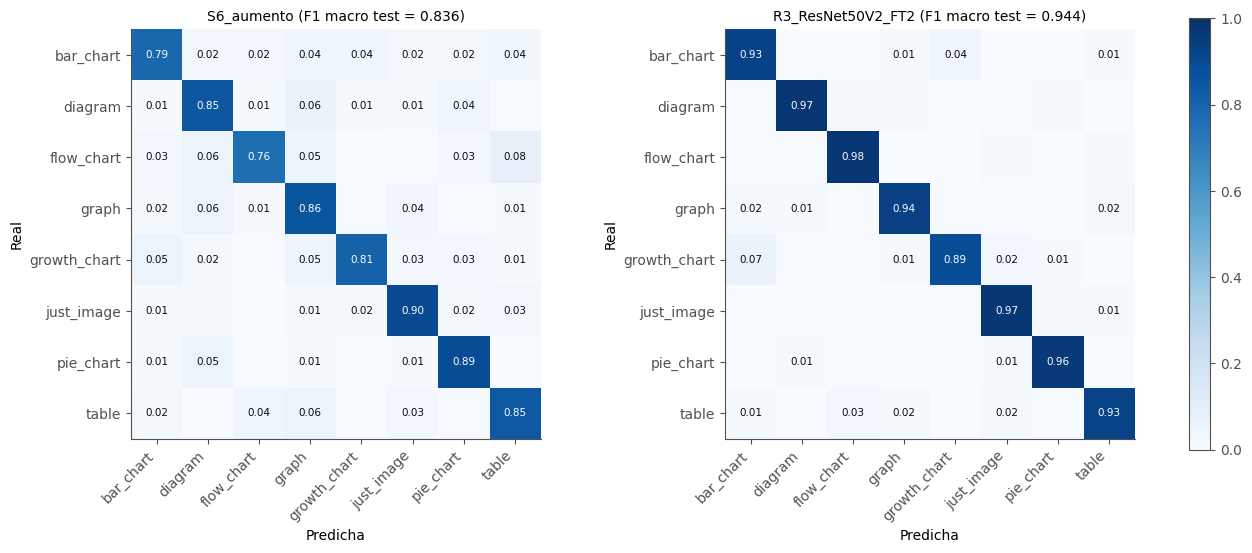

In [ ]:
MEJOR_GLOBAL = tabla_test.loc[[MEJOR_CERO, MEJOR_PRE], 'f1_macro_test'].idxmax()
fig, axs = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={'wspace': 0.45})
for ax, nombre in zip(axs, [MEJOR_CERO, MEJOR_PRE]):
    cm = confusion_matrix(y_test, predicciones[nombre], labels=range(N_CLASES), normalize='true')
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    for i in range(N_CLASES):
        for j in range(N_CLASES):
            if cm[i, j] >= 0.01:
                ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=7.5,
                        color='white' if cm[i, j] > 0.6 else '#0b0b0b')
    ax.set_xticks(range(N_CLASES), CLASES, rotation=45, ha='right')
    ax.set_yticks(range(N_CLASES), CLASES)
    ax.set_xlabel('Predicha'); ax.set_ylabel('Real'); ax.grid(False)
    ax.set_title(f'{nombre} (F1 macro test = {tabla_test.loc[nombre, "f1_macro_test"]:.3f})', fontsize=10)
fig.colorbar(im, ax=axs, fraction=0.025)
plt.show()

In [ ]:
for nombre in [MEJOR_CERO, MEJOR_PRE]:
    print(f'Informe por clase en test: {nombre}\n')
    print(classification_report(y_test, predicciones[nombre], labels=range(N_CLASES),
                                target_names=CLASES, digits=3, zero_division=0))

Informe por clase en test: S6_aumento

              precision    recall  f1-score   support

   bar_chart      0.850     0.785     0.817       289
     diagram      0.789     0.848     0.817       256
  flow_chart      0.872     0.758     0.811       252
       graph      0.767     0.856     0.809       285
growth_chart      0.817     0.807     0.812       166
  just_image      0.918     0.901     0.909       473
   pie_chart      0.858     0.890     0.874       272
       table      0.836     0.847     0.841       307

    accuracy                          0.844      2300
   macro avg      0.839     0.836     0.836      2300
weighted avg      0.846     0.844     0.844      2300

Informe por clase en test: R3_ResNet50V2_FT2

              precision    recall  f1-score   support

   bar_chart      0.921     0.927     0.924       289
     diagram      0.969     0.973     0.971       256
  flow_chart      0.946     0.976     0.961       252
       graph      0.950     0.937     0.943    

### Errores del mejor modelo

Una muestra de imágenes de test mal clasificadas por el mejor modelo, con la clase real y la predicha. Ayuda a distinguir errores del modelo de imágenes con etiqueta dudosa.

R3_ResNet50V2_FT2: 119 errores de 2300 imágenes de test


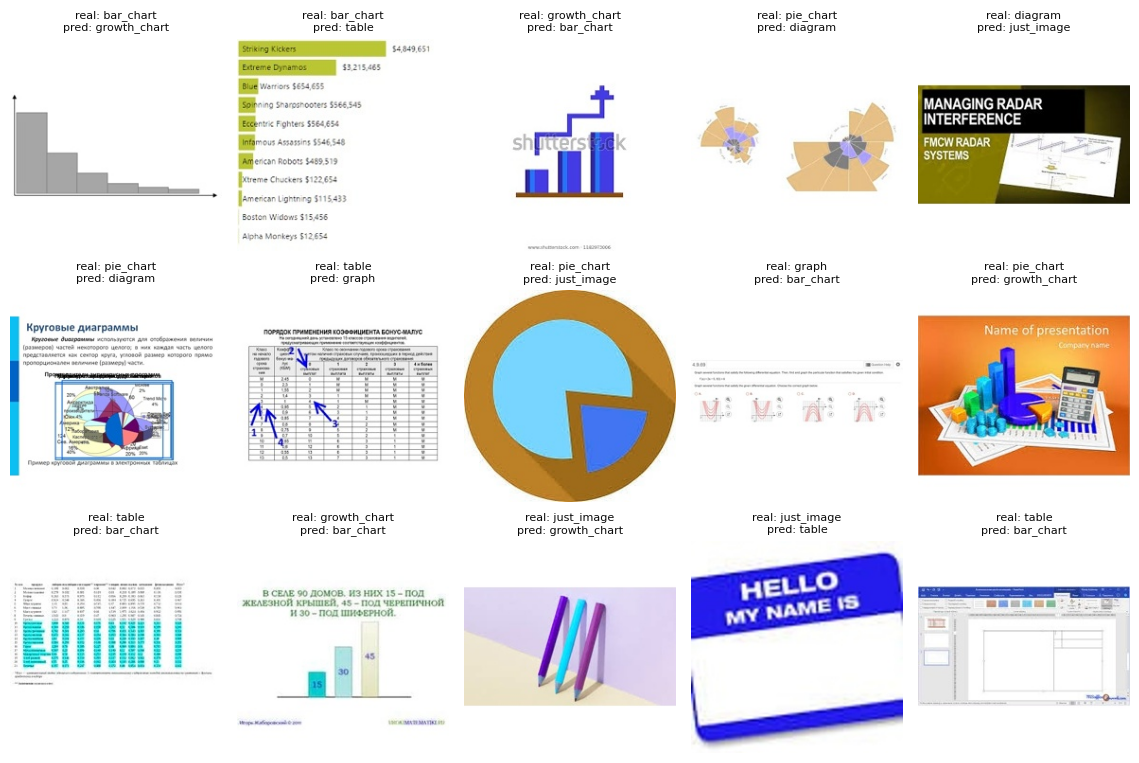

In [ ]:
errores = np.flatnonzero(predicciones[MEJOR_GLOBAL] != y_test)
print(f'{MEJOR_GLOBAL}: {len(errores)} errores de {len(y_test)} imágenes de test')
muestra = np.random.default_rng(SEED).choice(errores, size=min(15, len(errores)), replace=False)
if len(muestra):
    cols = 5
    filas_fig = int(np.ceil(len(muestra) / cols))
    fig, axs = plt.subplots(filas_fig, cols, figsize=(cols * 2.3, filas_fig * 2.6))
    axs = np.atleast_1d(axs).ravel()
    for ax in axs:
        ax.axis('off')
    for ax, i in zip(axs, muestra):
        ax.axis('on')
        mostrar(ax, test_df.ruta_proc.values[i],
                f'real: {CLASES[y_test[i]]}\npred: {CLASES[predicciones[MEJOR_GLOBAL][i]]}')
    plt.tight_layout()
    plt.show()

### Coste de cada estrategia

In [ ]:
coste = pd.DataFrame(resultados).T.groupby('estrategia').agg(
    experimentos=('minutos', 'size'), minutos_totales=('minutos', 'sum'))
coste['minutos_totales'] = coste.minutos_totales.astype(float).round(1)
display(coste)
display(tabla_test.loc[[MEJOR_CERO, MEJOR_MNV, MEJOR_RN], ['parametros', 'ms_por_imagen', 'f1_macro_test']])

,experimentos,minutos_totales
estrategia,,
desde cero,7,21.8
preentrenada,7,60.2


,parametros,ms_por_imagen,f1_macro_test
modelo,,,
S6_aumento,4288712,1.532,0.836
M4_MobileNetV2_FT2,2268232,5.959,0.941
R3_ResNet50V2_FT2,23581192,7.538,0.944


## Conclusiones

Las dos estrategias quedan muy por encima de los clasificadores triviales. En test, el que predice siempre la clase más frecuente obtiene un F1 macro de 0,043 y el que predice al azar, 0,136. La mejor red desde cero (S6) llega a 0,836, y las preentrenadas con *fine-tuning*, a 0,941 (MobileNetV2) y 0,944 (ResNet50V2). Partir de ImageNet reduce los errores a la tercera parte: S6 falla en el 15,6 % de las imágenes de test y ResNet50V2 en 119 de 2.300 (5,2 %).

En la estrategia 1 la decisión con más efecto fue el aumento de datos, que subió el F1 en 0,056. Los cambios de arquitectura y la regularización explícita no mejoraron la validación, y la *batch normalization* volvió inestable el entrenamiento. En la estrategia 2 la base congelada ya superaba a cualquier red desde cero, y el *fine-tuning* añadió unos tres puntos en las dos arquitecturas. En MobileNetV2 el segundo tramo descongelado no aportó nada; en ResNet50V2, sí.

Ningún modelo final sobreajusta de forma preocupante. Las brechas entre entrenamiento y validación van de 0,041 a 0,052, y la diferencia de F1 entre validación y test es como mucho de 0,008 (S6: 0,844 y 0,836; MobileNetV2: 0,937 y 0,941; ResNet50V2: 0,950 y 0,944). Elegir los modelos con validación no la ha sesgado, y las cifras de test son una estimación fiable.

La red desde cero reparte sus errores entre muchas clases; las más difíciles son `flow_chart` (*recall* de 0,76) y `bar_chart` (0,79). ResNet50V2 acierta más del 92 % de las imágenes de cada clase salvo en `growth_chart` (0,89), que confunde sobre todo con `bar_chart`. Las dos clases se solapan, porque muchos `growth_chart` son gráficos de barras con tendencia creciente. En la muestra de errores hay varios casos en que la etiqueta es discutible: un gráfico de barras horizontales lleno de cifras que el modelo toma por una tabla, un gráfico polar etiquetado como `pie_chart` o una foto de tres bolígrafos de alturas crecientes clasificada como `growth_chart`. Parte del error que queda parece venir del etiquetado más que del modelo.

La red desde cero es la estrategia más barata. Tiene 4,3 millones de parámetros, los siete experimentos tardaron 22 minutos y clasifica una imagen en 1,5 ms, con entradas de 128 píxeles que caben en memoria. Su límite es el rendimiento, que con unas 10.700 imágenes de entrenamiento se queda en 0,84. Las preentrenadas necesitan imágenes de 224 píxeles, que hubo que leer del disco en cada época para no agotar la memoria de Colab, y casi el triple de tiempo de entrenamiento (60 minutos en total). A cambio dan unos diez puntos más de F1. Entre ellas, MobileNetV2 consigue casi lo mismo que ResNet50V2 (0,941 frente a 0,944 en test) con diez veces menos parámetros y algo menos de tiempo por imagen (6,0 frente a 7,5 ms).

Para este problema la estrategia recomendada es *transfer learning* seguido de *fine-tuning*. ResNet50V2 con dos tramos descongelados es el mejor modelo obtenido, pero la arquitectura recomendada es MobileNetV2: en test la diferencia es de 0,003, menor de lo que varían los resultados entre ejecuciones, y el modelo es mucho más ligero y rápido de entrenar.

Como limitación, cada configuración se entrenó una sola vez. En GPU los resultados cambian ligeramente entre ejecuciones, así que diferencias de alrededor de 0,01 (S7 frente a S6, FT2 frente a FT1 en MobileNetV2 o las dos arquitecturas en test) no permiten decidir cuál es mejor. Los siguientes pasos serían repetir cada experimento con varias semillas, dar más épocas a S2 y probar la *batch normalization* con otra tasa de aprendizaje.

## Generación del PDF

Convierte el fichero guardado en la carpeta `Colab Notebooks/07MIAR_Proyecto_Programacion` de Drive con el nombre indicado, con las salidas que tenga guardadas. El PDF queda en esa misma carpeta.

In [1]:
import sys
NOMBRE_NOTEBOOK = '07MIAR_Proyecto_Graphs.ipynb'
CARPETA_DRIVE = '/content/drive/MyDrive/Colab Notebooks/07MIAR_Proyecto_Programacion'
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    !apt-get -qq update > /dev/null && apt-get -qq install -y texlive-xetex texlive-fonts-recommended texlive-plain-generic pandoc > /dev/null
    !jupyter nbconvert --to pdf --output-dir "$CARPETA_DRIVE" "$CARPETA_DRIVE/$NOMBRE_NOTEBOOK"
else:
    print('La conversión a PDF de la entrega se hace en Colab.')

Mounted at /content/drive
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/07MIAR_Proyecto_Programacion/07MIAR_Proyecto_Graphs.ipynb to pdf
[NbConvertApp] Support files will be in 07MIAR_Proyecto_Graphs_files/
[NbConvertApp] Making directory ./07MIAR_Proyecto_Graphs_files
[NbConvertApp] Writing 235635 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 2633254 bytes to /content/drive/MyDrive/Colab Notebooks/07MIAR_Proyecto_Programacion/07MIAR_Proyecto_Graphs.pdf
